# Respuesta farmacológica multimodal · versión estable v1
**Reproducción desde datos originales en un entorno aislado · octubre de 2026.**

Este notebook presenta los seis modelos del protocolo congelado, cinco folds de
fármacos nuevos, transferencia GDSC→PRISM, armonización y calibración independiente.
Los IDs con la misma identidad química completa (InChIKey) permanecen juntos
en cada partición cold-drug y en la reserva de calibración.
Las métricas macro por fármaco conservan los IDs de los registros originales;
el bootstrap agrupa las identidades químicas para mantener juntos sus alias.
Cada modelo se ha guardado y recargado para verificar sus predicciones.
El escalado y PCA se ajustan en float64 con BLAS fijado internamente a ocho
hilos sobre células de entrenamiento; las
características finales se convierten a float32. Se comprueba la estabilidad
de las proyecciones entre 8 y 16 hilos de BLAS sin usar respuestas del test.
Las figuras se regeneran desde el informe compacto; el notebook no reentrena.
Las «dianas» son anotaciones putativas que incluyen genes, familias y mecanismos.

RMSE menor indica mejor predicción. Los resultados de IC50 y AUC tienen escalas
distintas. PRISM es una evaluación exploratoria ya examinada; no constituye una
validación clínica. Las demás arquitecturas permanecen experimentales.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from IPython.display import display, Image

HERE = Path.cwd()
REPORT = next((p for p in [HERE / "reports/stable_v1_summary.json",
    HERE / "data/reports/stable_v1_summary.json",
    HERE.parent / "data/reports/stable_v1_summary.json"] if p.exists()), None)
if REPORT is None:
    raise FileNotFoundError("No se encuentra el informe estable v1.")
s = json.loads(REPORT.read_text(encoding="utf-8"))
assert s["status"] in {"models_validated", "validated"} and s["models_reloaded"] == 60
metrics = pd.DataFrame(s["metrics"])
agg = pd.DataFrame(s["aggregate_test"]).sort_values("rmse_mean")
main_check = metrics.loc[metrics.case.str.fullmatch(r"cold_drug_fold_\d") & metrics.subset.eq("test")]
for row in agg.itertuples():
    selected = main_check.loc[main_check.stage.eq(row.stage) & main_check.model.eq(row.model)]
    assert len(selected) == 5 and np.isclose(selected.rmse.mean(), row.rmse_mean, atol=1e-10)
assert len(s["out_of_fold_coverage"]) == 6
assert set(s["out_of_fold_coverage"].values()) == {149364}
MODEL_LABELS = {"mean_effects": "Efectos medios", "targets_expression_pca": "Dianas + PCA",
    "morgan_expression_pca": "Morgan + PCA", "pretrained_drug_expression_pca": "ChemBERTa + PCA"}
CASE_ORDER = ["published_transfer", "matched_published_transfer", "harmonized_transfer"]
CASE_LABELS = {"published_transfer": "AUC publicada · total",
    "matched_published_transfer": "AUC publicada · mismos pares",
    "harmonized_transfer": "AUC armonizada · mismos pares"}
METHOD_LABELS = {"raw": "Sin ajuste", "affine_validation": "Ajuste afín (validación)"}
def pretty_model(value):
    stage, name = value.split(" · ", 1)
    return stage + " · " + MODEL_LABELS.get(name, name)
def label(frame):
    return frame.stage + " · " + frame.model.map(MODEL_LABELS)
agg["label"] = label(agg)
REPORT_ROOT = REPORT.parent.parent
if REPORT_ROOT.name == "data":
    REPORT_ROOT = REPORT_ROOT.parent
OUT = REPORT_ROOT / "figures/stable_v1"
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "figure.facecolor": "white",
    "pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none"})
exports = []
def save(fig, name):
    fig.tight_layout()
    for suffix in ("png", "svg", "pdf"):
        path = OUT / f"{name}.{suffix}"
        fig.savefig(path, dpi=300, bbox_inches="tight")
        exports.append(str(path))
    display(Image(filename=str(OUT / f"{name}.png")))
    plt.close(fig)
display(agg[["label", "rmse_mean", "rmse_std", "spearman_mean", "r2_normalized_mean", "spearman_per_drug_mean", "n_folds"]])


,label,rmse_mean,rmse_std,spearman_mean,r2_normalized_mean,spearman_per_drug_mean,n_folds
5,RF · Dianas + PCA,2.362372,0.500490,0.503405,0.220903,0.650130,5
4,RF · Morgan + PCA,2.471001,0.560860,0.437473,0.155783,0.636101,5
2,B6 · Dianas + PCA,2.525142,0.455381,0.408506,0.101091,0.554373,5
3,B7 · ChemBERTa + PCA,2.624550,0.354006,0.299453,0.033267,0.503760,5
1,B6 · Morgan + PCA,2.672362,0.469893,0.320860,-0.006379,0.499062,5
0,B0 · Efectos medios,2.688546,0.456061,0.343221,0.000000,0.620078,5


## Preprocessing y separación de datos
El filtrado de genes de baja varianza, escalado y PCA se ajustan solo sobre células de entrenamiento. La tabla muestra los objetos recargados y su reproducción desde la expresión original. En cold-drug se retienen fármacos nuevos, por lo que las células pueden ser conocidas. La validación selecciona los modelos; la calibración reserva entidades adicionales y el test se evalúa después.

In [2]:
display(pd.DataFrame(s["preprocessing_reloaded"]))
print("IDs de fármacos:", s["chemistry"]["drug_ids"],
      "· identidades químicas:", s["chemistry"]["chemical_identities"])
display(pd.DataFrame(s["chemistry"]["aliases"]))

,case,max_abs_delta,cells,train_cells,genes_retained,pca_components,explained_variance,computation_dtype,blas_threads,status
0,cold_drug_fold_0,0.0,717,717,19198,256,0.803249,float64,8,verified
1,cold_drug_fold_0_calibration,0.0,717,717,19198,256,0.803249,float64,8,verified
2,cold_drug_fold_1,0.0,717,717,19198,256,0.803249,float64,8,verified
3,cold_drug_fold_1_calibration,0.0,717,717,19198,256,0.803249,float64,8,verified
4,cold_drug_fold_2,0.0,717,717,19198,256,0.803249,float64,8,verified
5,cold_drug_fold_2_calibration,0.0,717,717,19198,256,0.803249,float64,8,verified
6,cold_drug_fold_3,0.0,717,717,19198,256,0.803249,float64,8,verified
7,cold_drug_fold_3_calibration,0.0,717,717,19198,256,0.803249,float64,8,verified
8,cold_drug_fold_4,0.0,717,717,19198,256,0.803249,float64,8,verified
9,cold_drug_fold_4_calibration,0.0,717,717,19198,256,0.803249,float64,8,verified


IDs de fármacos: 238 · identidades químicas: 229


,chemical_id,drug_ids
0,AXTAPYRUEKNRBA-UHFFFAOYSA-N,"[1553, 2106]"
1,CYOHGALHFOKKQC-UHFFFAOYSA-N,"[1062, 1736]"
2,DRMCATBEKSVAPL-UHFFFAOYSA-N,"[1089, 1806]"
3,KSERXGMCDHOLSS-UHFFFAOYSA-N,"[1908, 2047]"
4,PHPUXYRXPHEJDF-UHFFFAOYSA-N,"[1803, 1804]"
5,RJURFGZVJUQBHK-UHFFFAOYSA-N,"[1811, 1911]"
6,ULNXAWLQFZMIHX-UHFFFAOYSA-N,"[1627, 2037]"
7,VWUXBMIQPBEWFH-UHFFFAOYSA-N,"[1200, 1816]"
8,ZDZOTLJHXYCWBA-UHFFFAOYSA-N,"[1007, 1819]"


In [3]:
populations = pd.DataFrame(s["split_populations"])
display(populations.loc[populations.case.str.fullmatch(r"cold_drug_fold_\d")])
display(populations.loc[populations.subset.eq("calibration")])

,case,subset,pairs,drug_ids,chemical_identities,cells
0,cold_drug_fold_0,test,30014,47,46,717
1,cold_drug_fold_0,train,88989,144,137,717
2,cold_drug_fold_0,validation,30361,47,46,716
7,cold_drug_fold_1,test,30361,47,46,716
8,cold_drug_fold_1,train,88242,143,137,717
9,cold_drug_fold_1,validation,30761,48,46,717
14,cold_drug_fold_2,test,30761,48,46,717
15,cold_drug_fold_2,train,88496,141,137,717
16,cold_drug_fold_2,validation,30107,49,46,717
21,cold_drug_fold_3,test,30107,49,46,717


,case,subset,pairs,drug_ids,chemical_identities,cells
3,cold_drug_fold_0_calibration,calibration,14416,24,21,717
10,cold_drug_fold_1_calibration,calibration,13978,23,21,715
17,cold_drug_fold_2_calibration,calibration,14135,22,21,717
24,cold_drug_fold_3_calibration,calibration,14184,22,21,717
31,cold_drug_fold_4_calibration,calibration,13712,22,21,716
38,harmonized_transfer_calibration,calibration,1362,23,23,93


## 1. Rendimiento en fármacos nuevos
Media y desviación entre folds; la dispersión no es un intervalo de confianza.

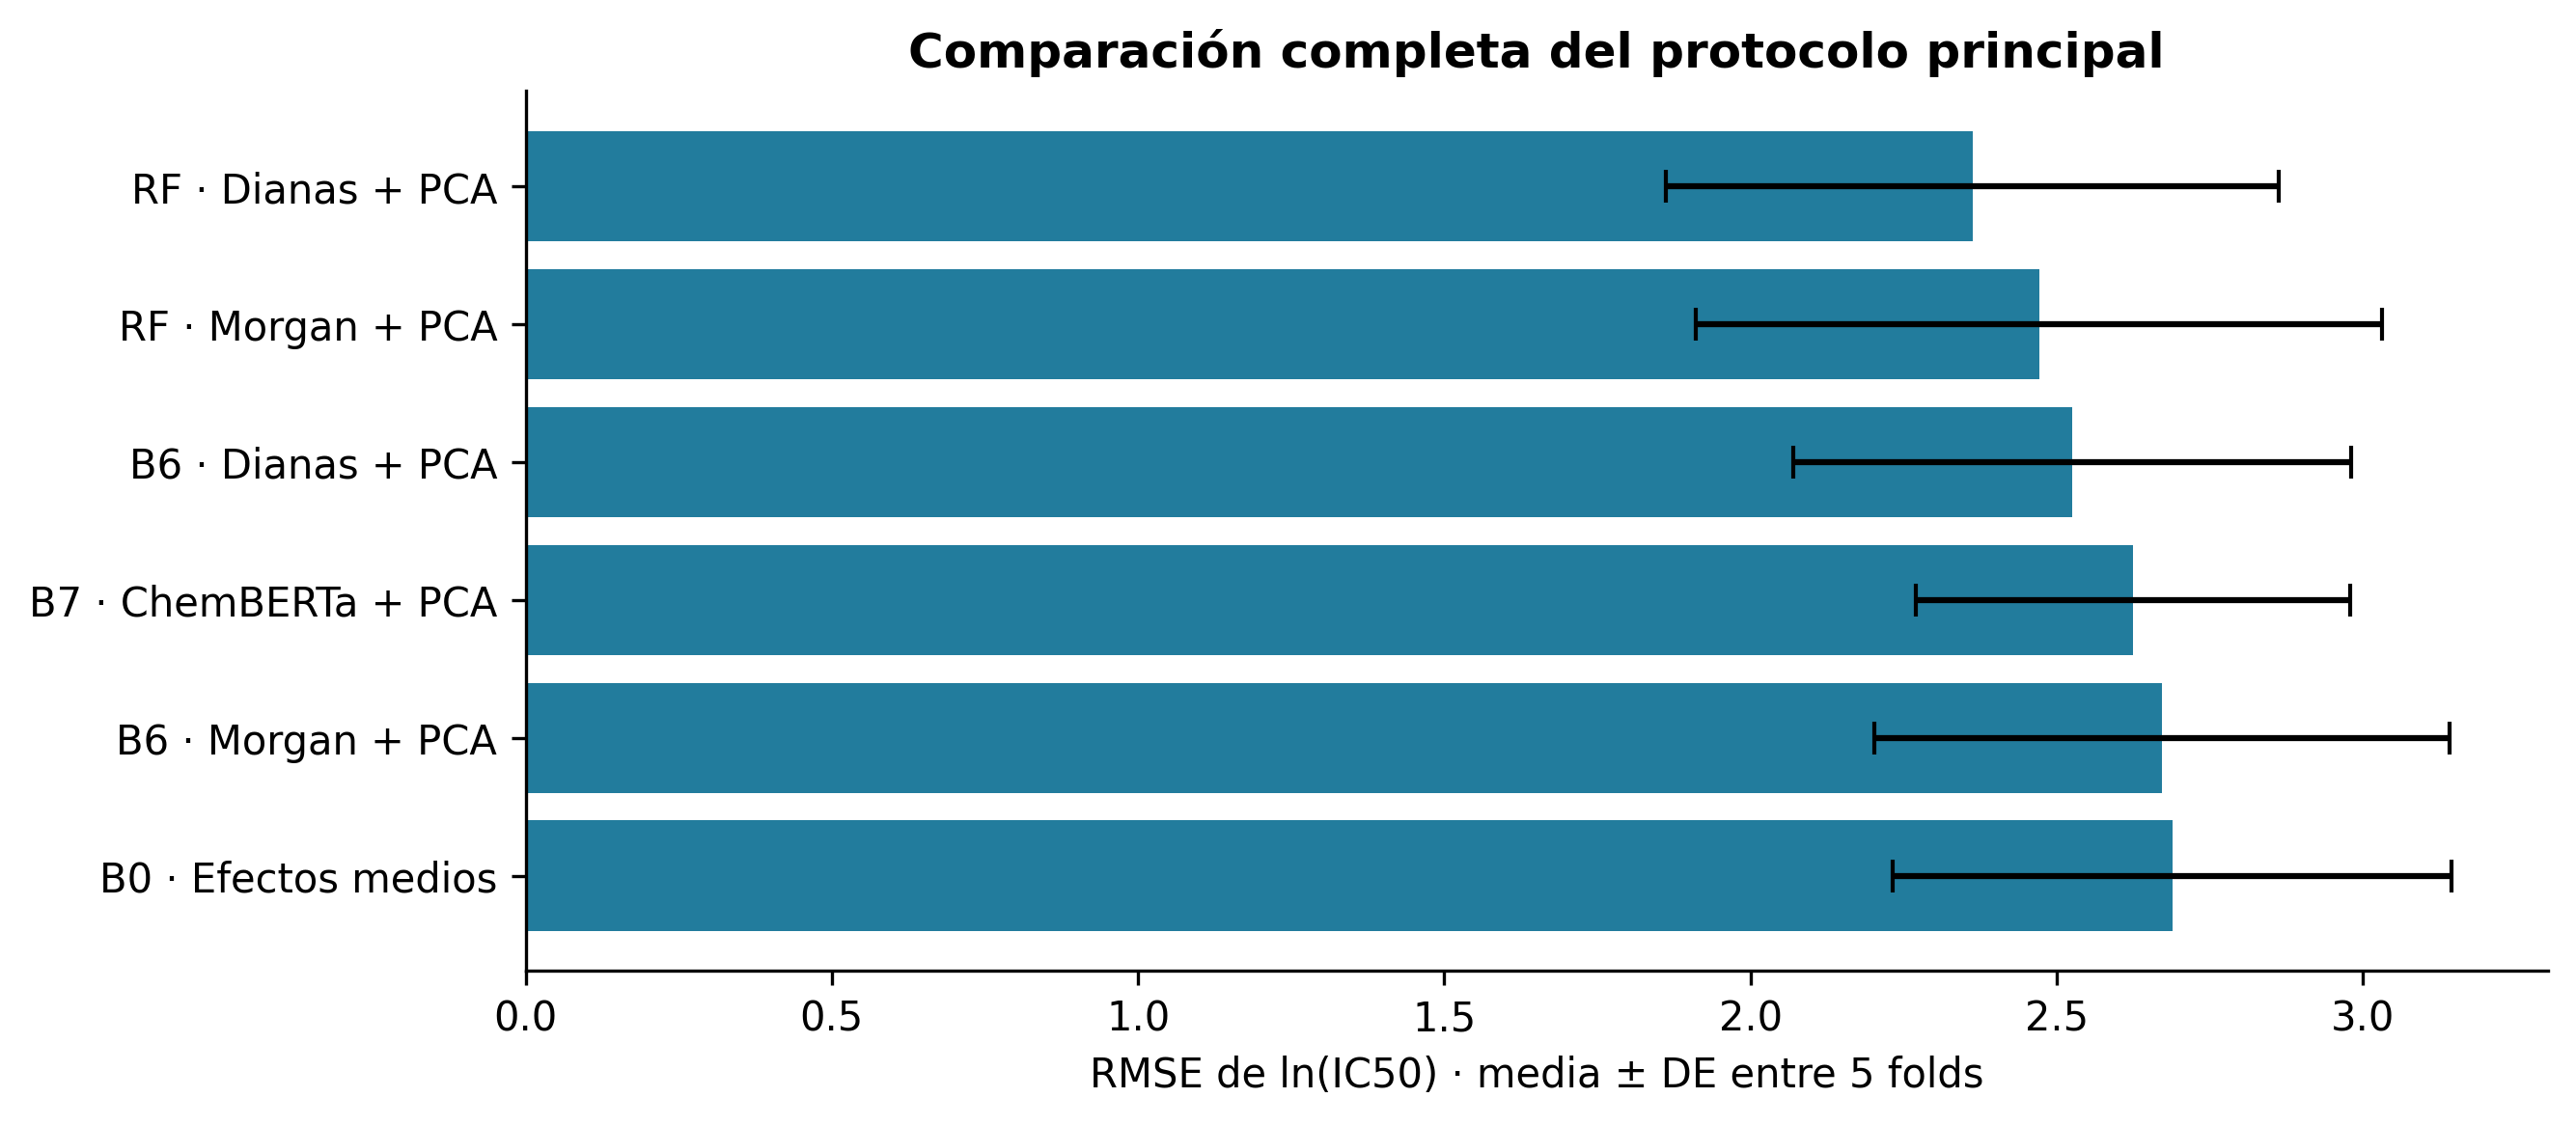

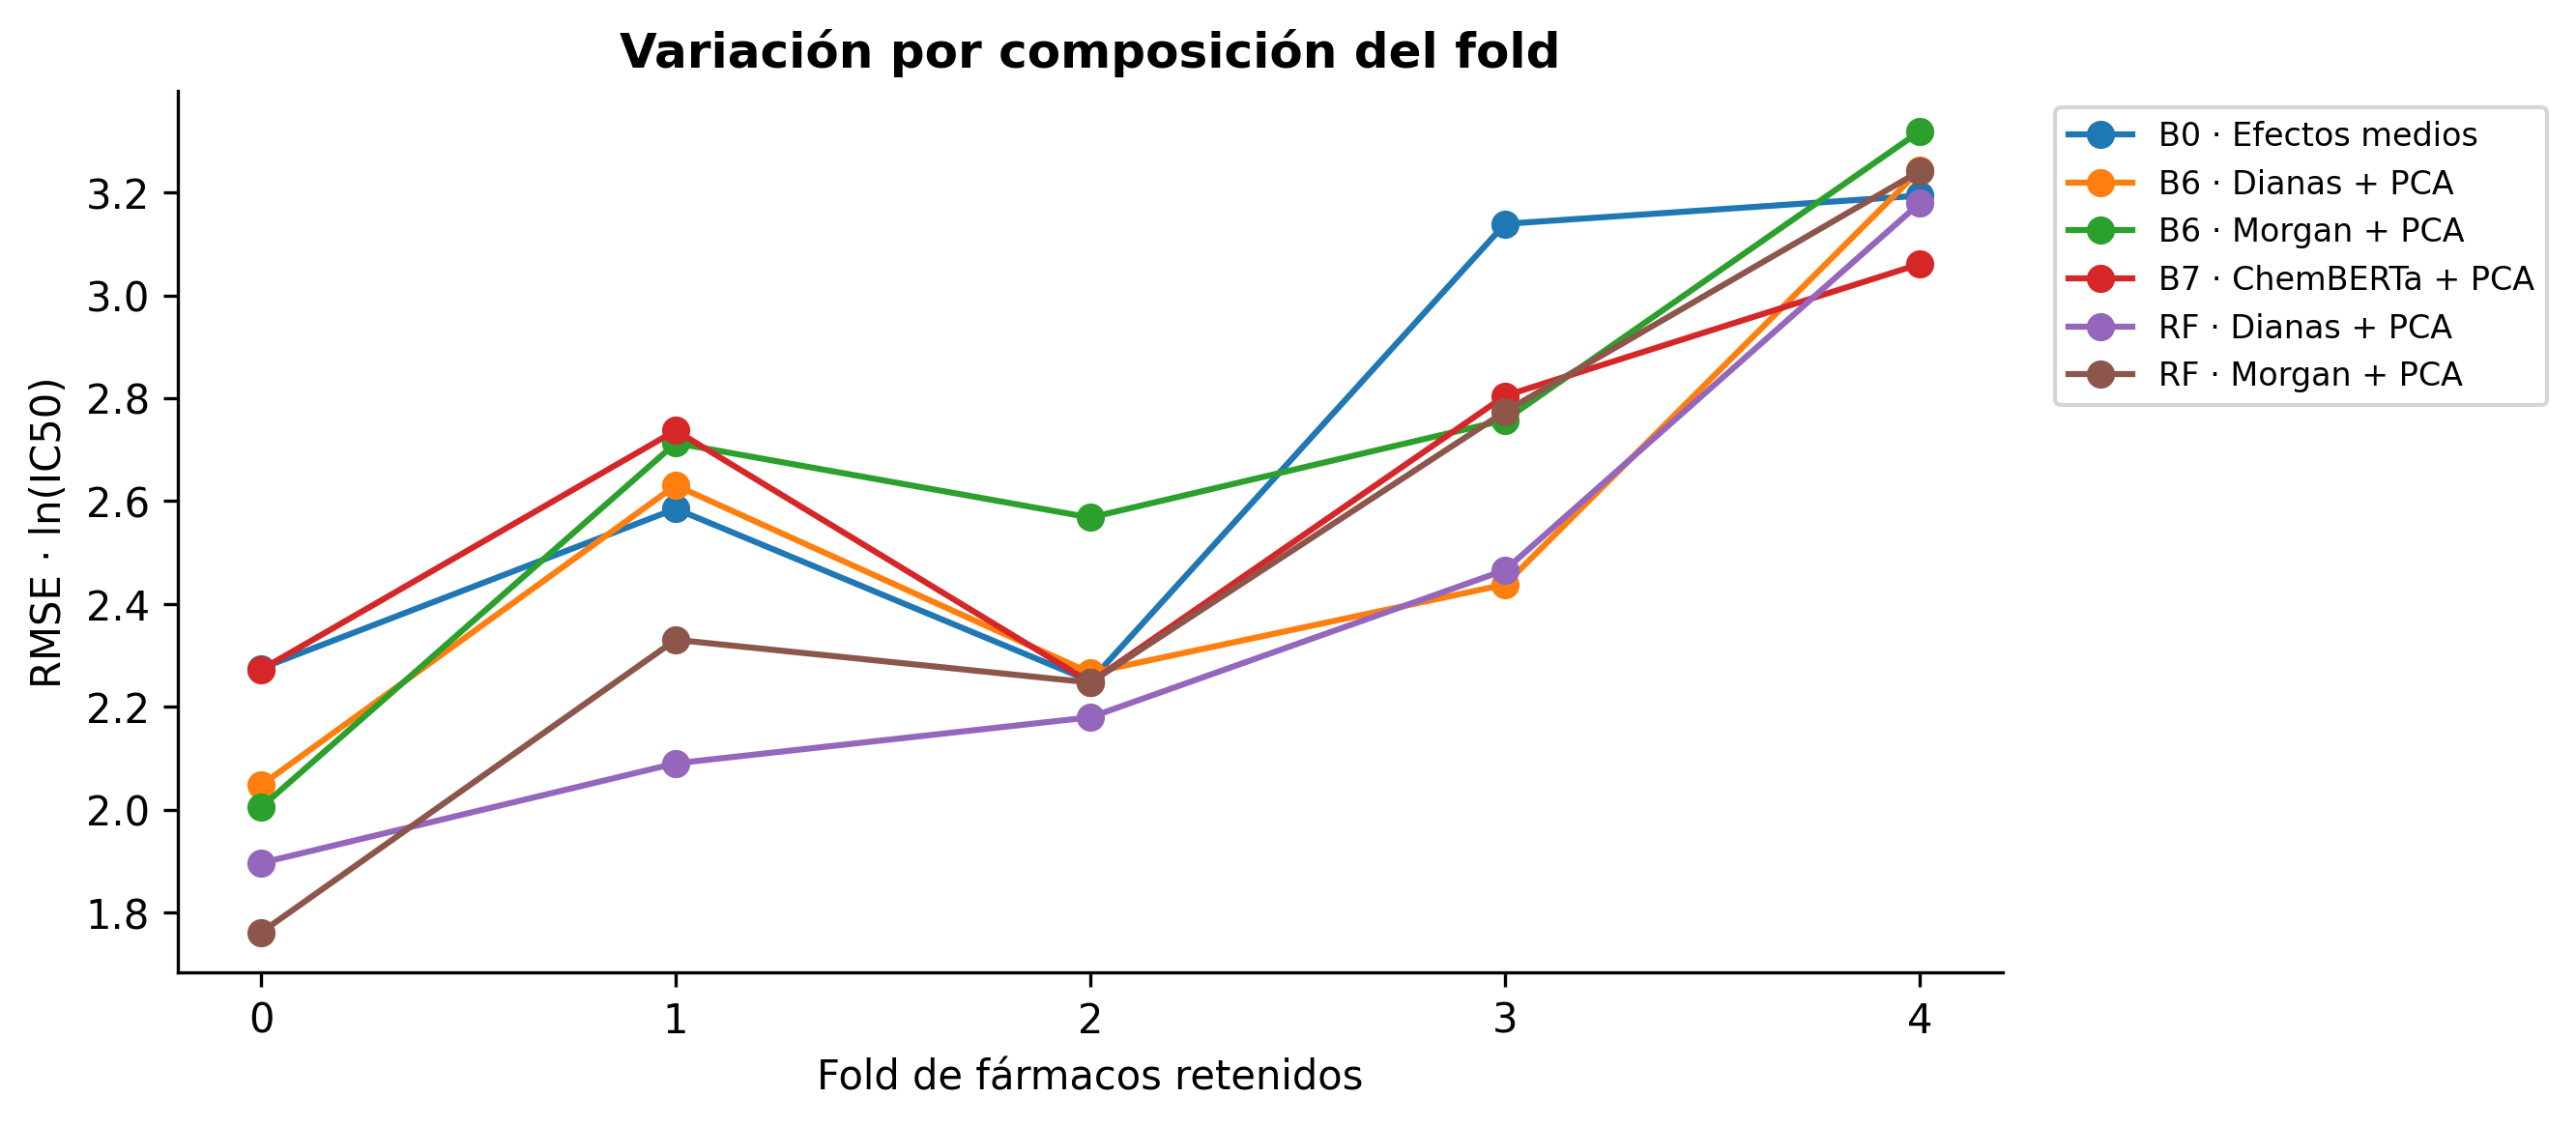

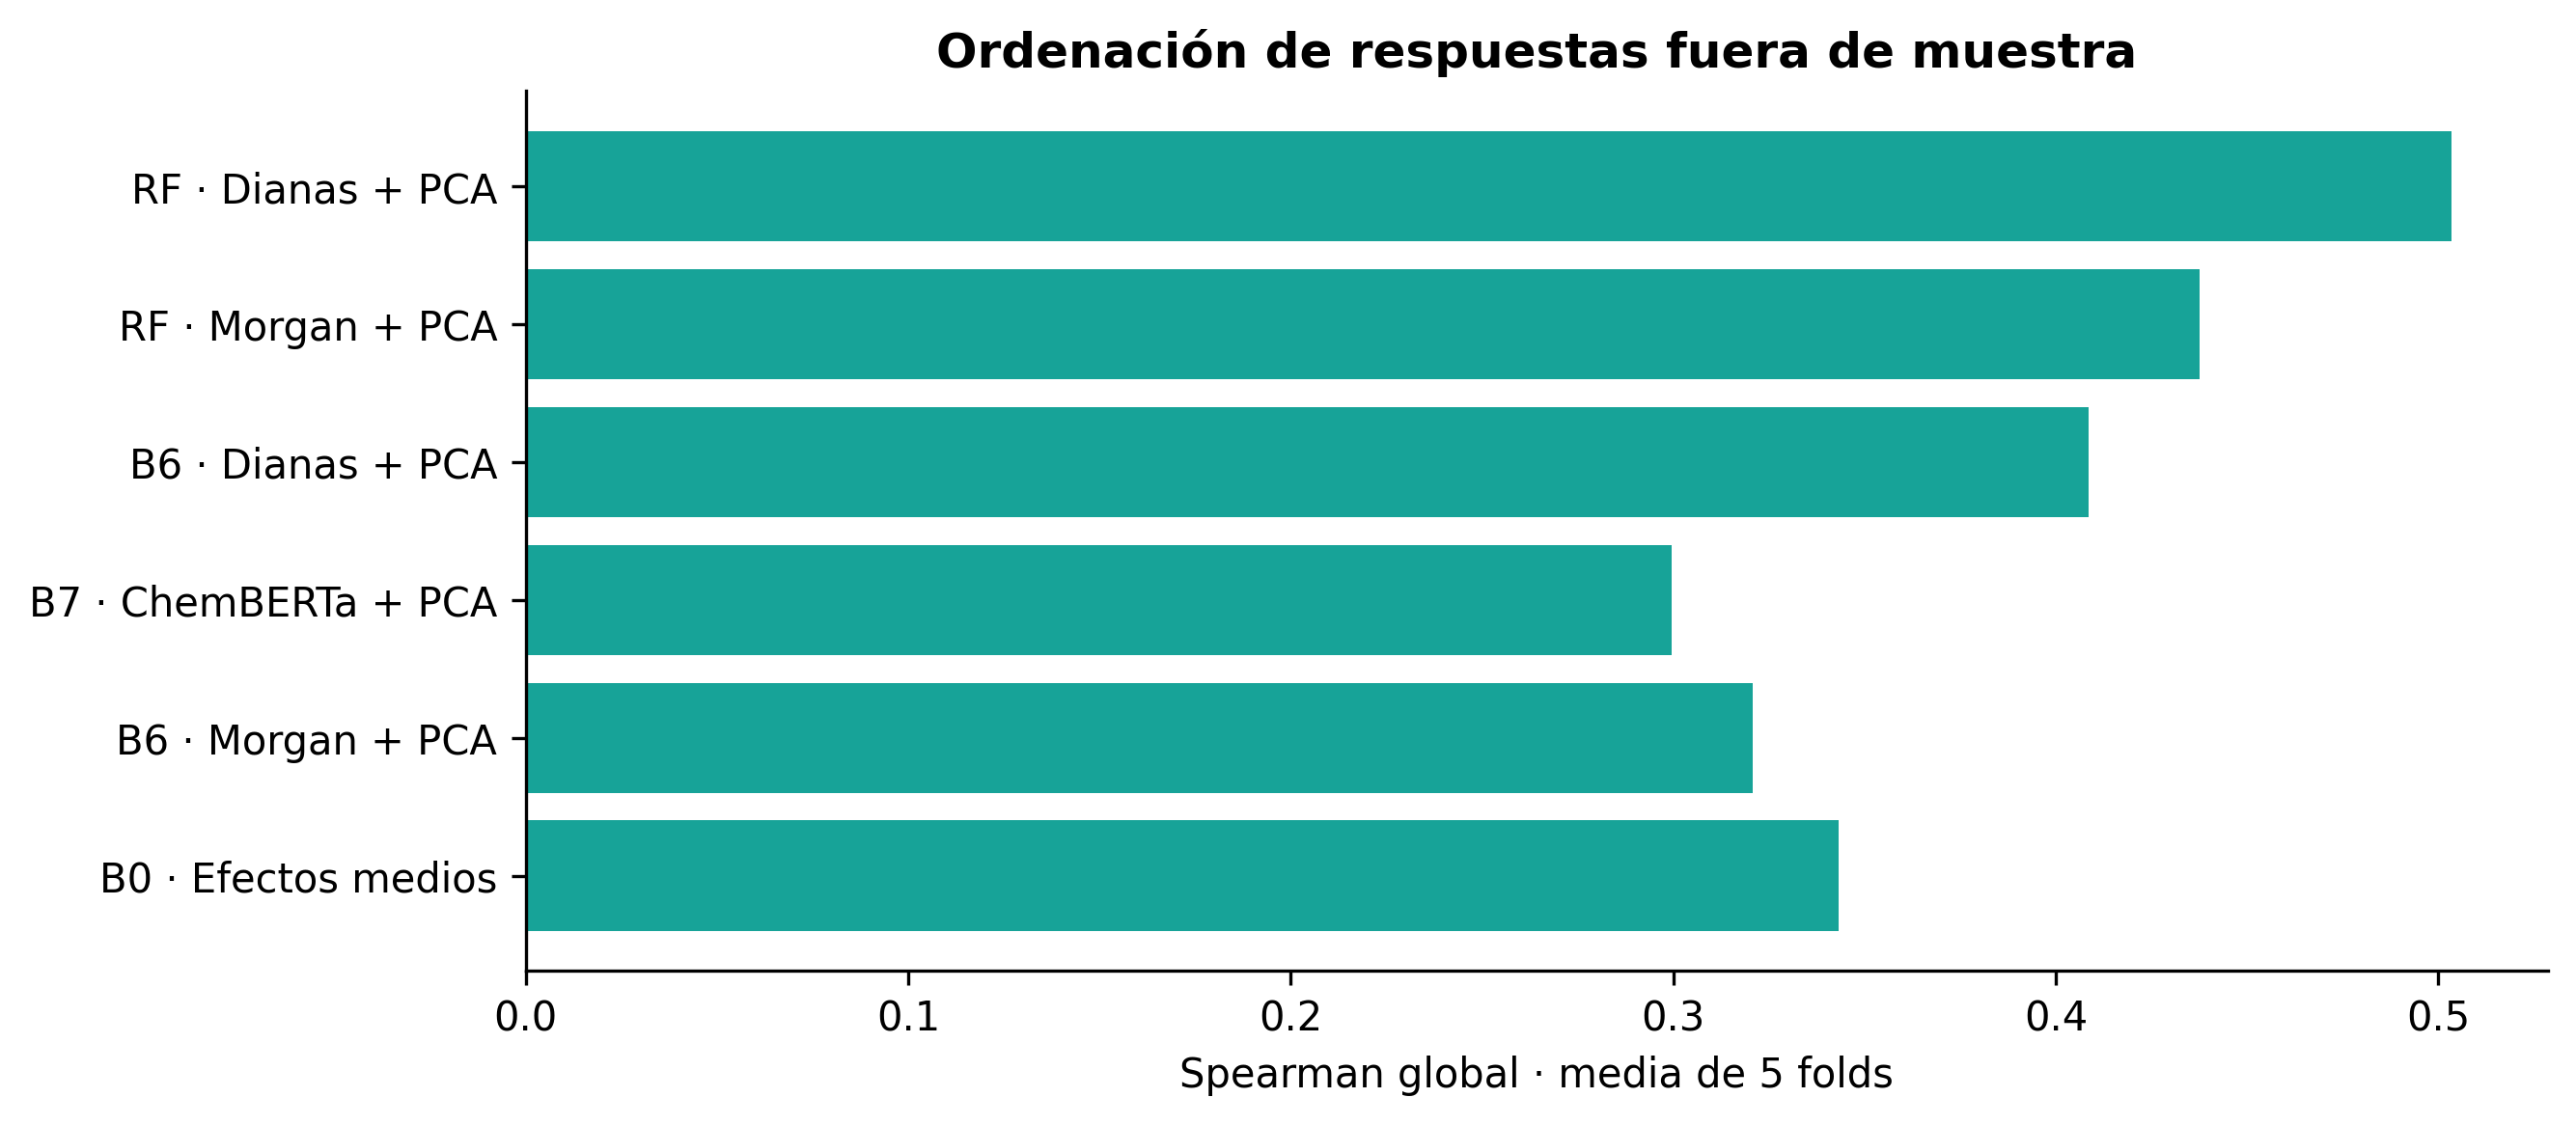

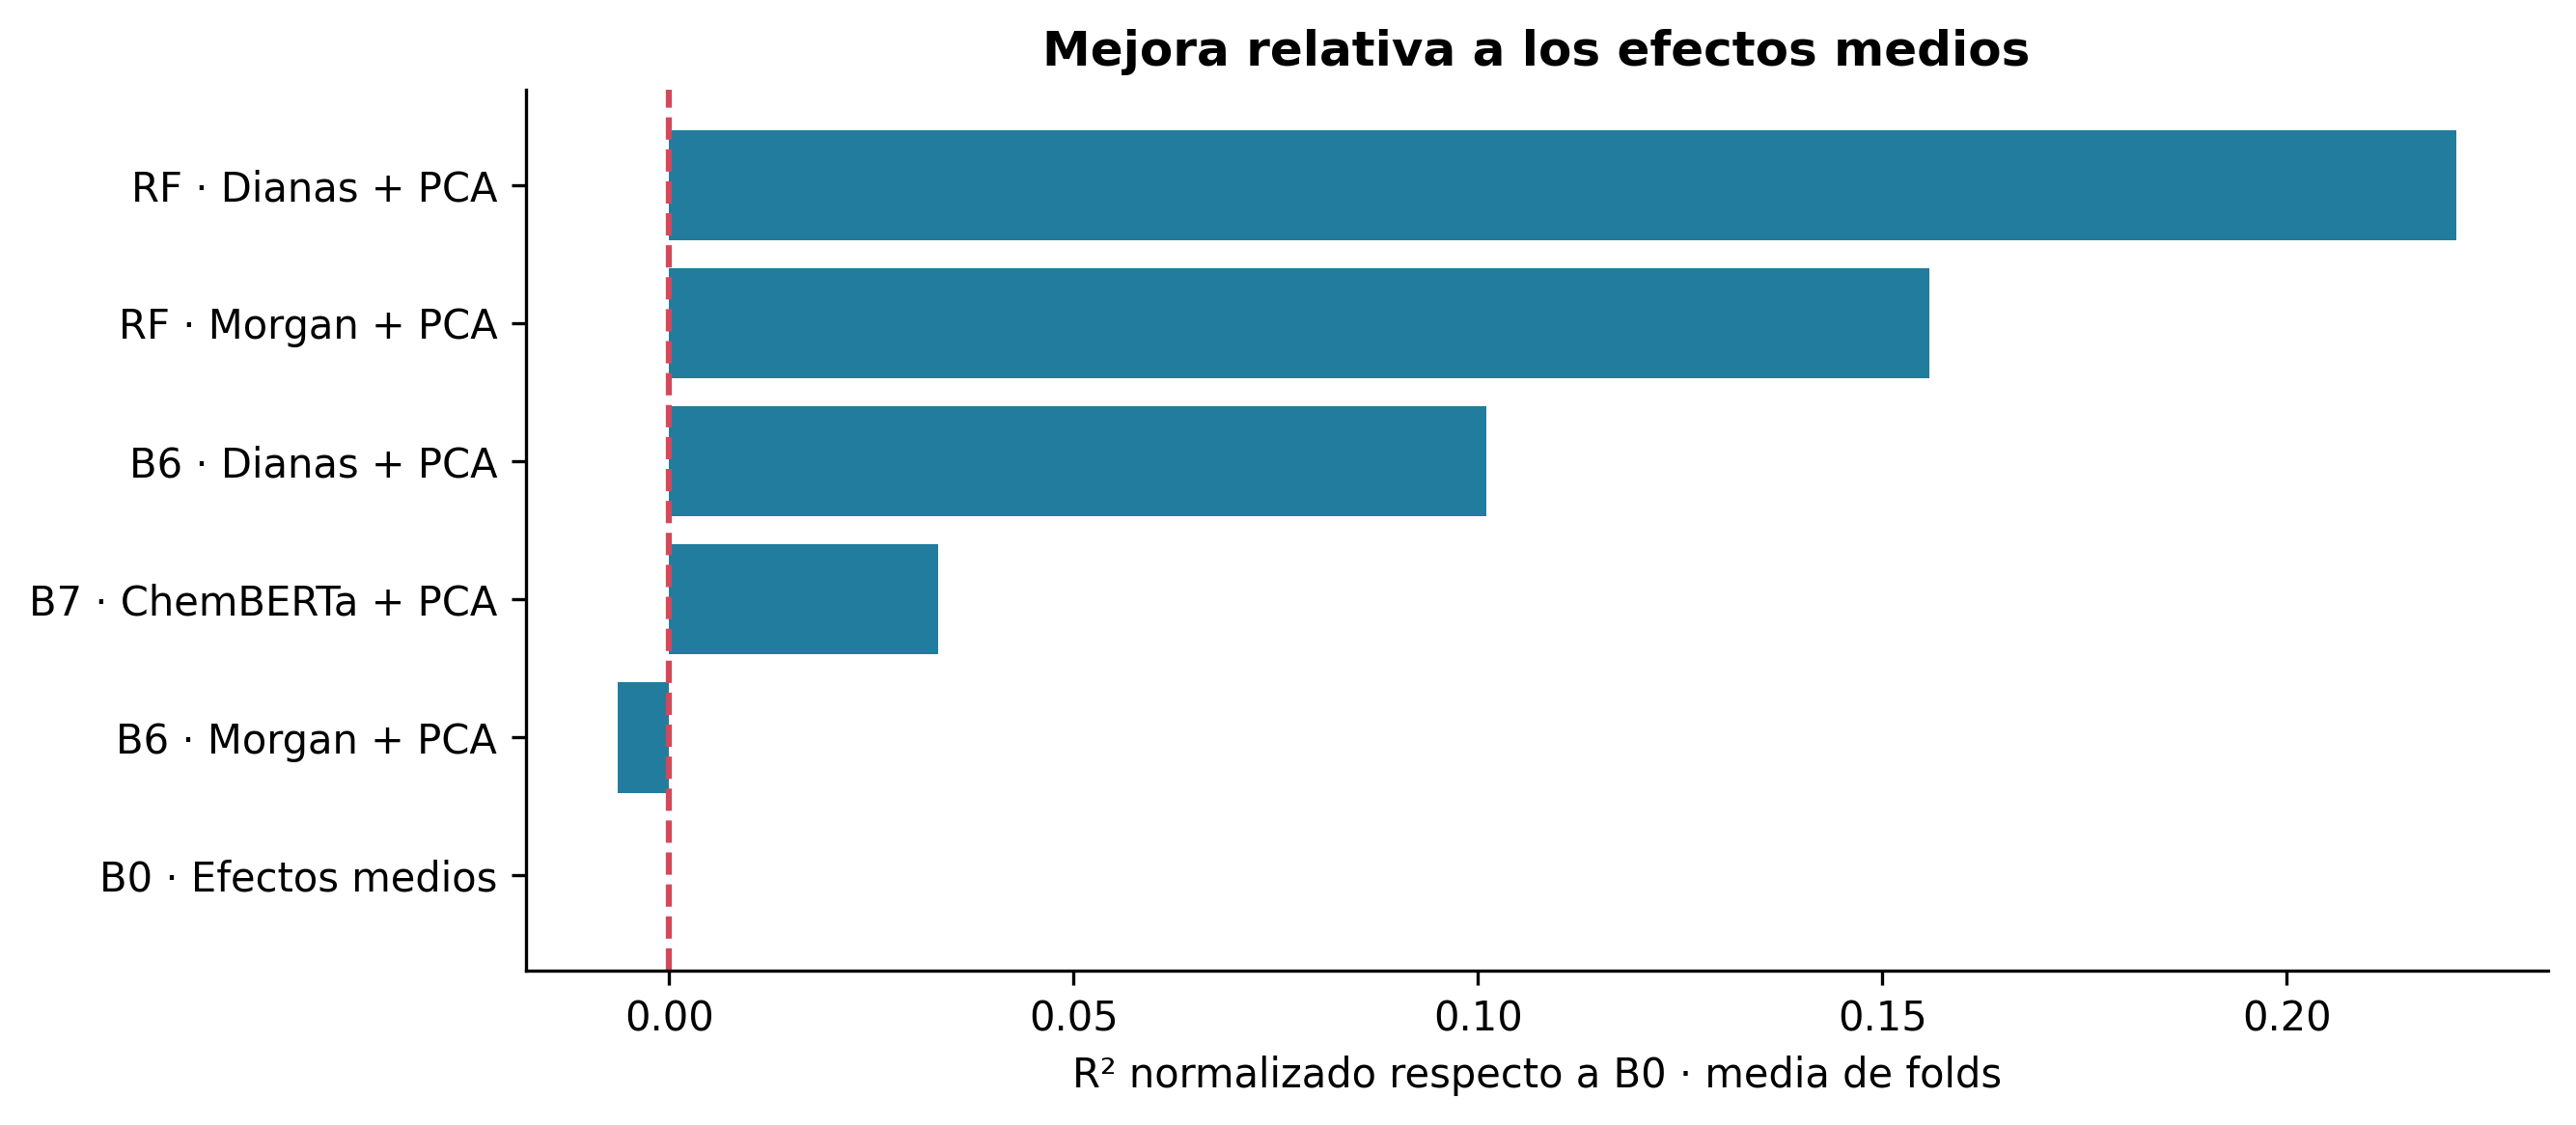

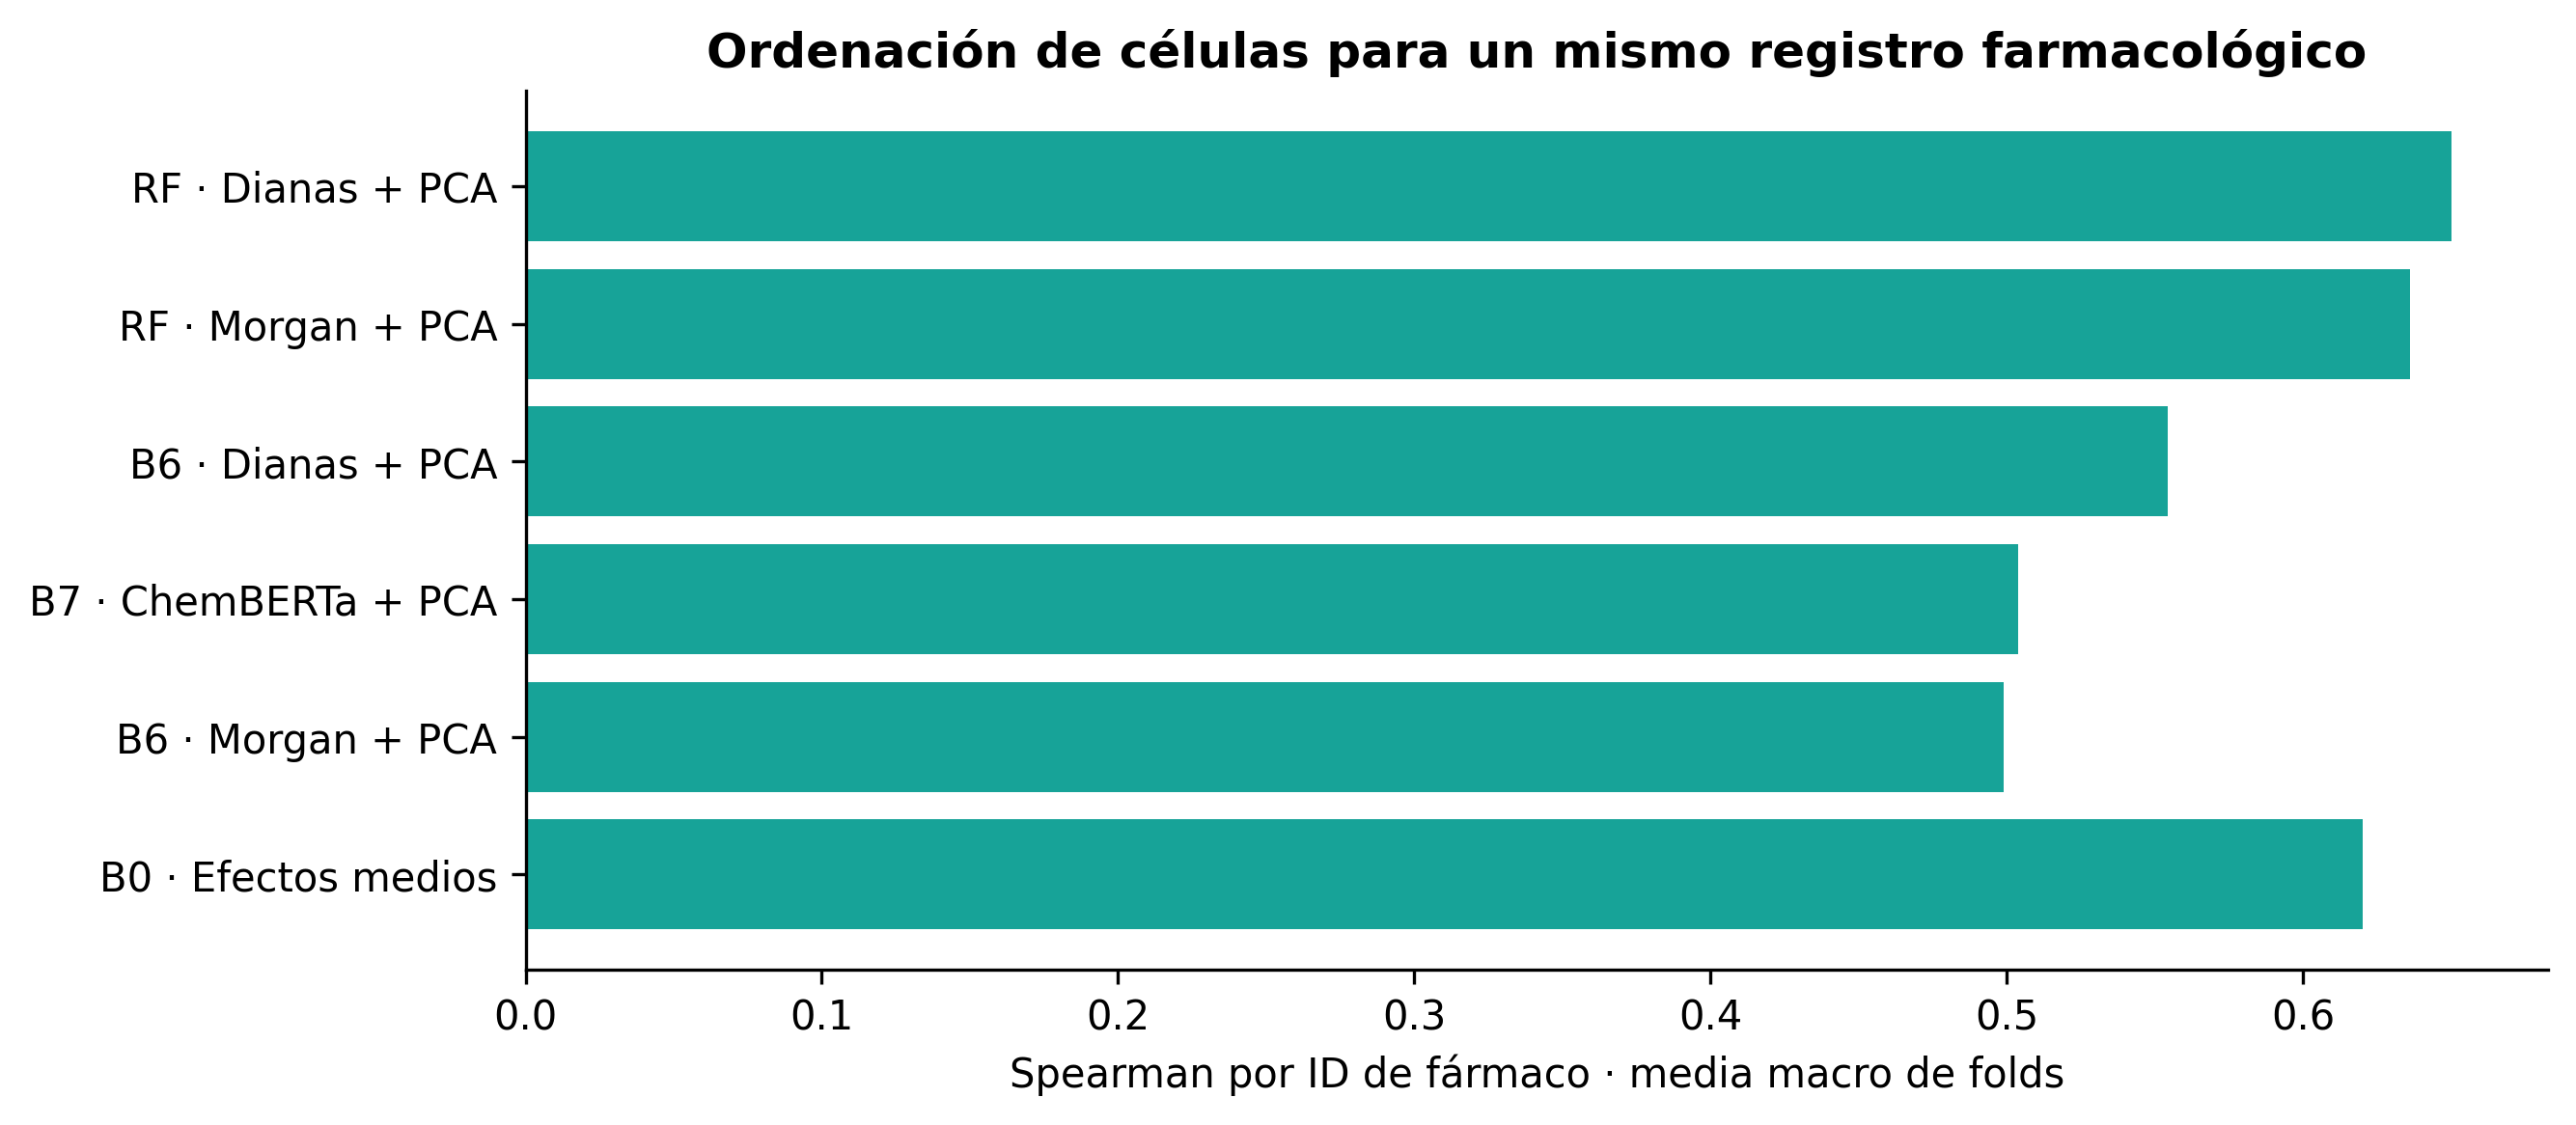

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(agg.label, agg.rmse_mean, xerr=agg.rmse_std, color="#227C9D", capsize=4)
ax.invert_yaxis()
ax.set(xlabel="RMSE de ln(IC50) · media ± DE entre 5 folds", title="Comparación completa del protocolo principal")
save(fig, "01_cold_drug_rmse")
main = metrics.loc[metrics.case.str.fullmatch(r"cold_drug_fold_\d") & metrics.subset.eq("test")].copy()
main["label"] = label(main)
fig, ax = plt.subplots(figsize=(9, 4))
for name, rows in main.groupby("label"):
    ax.plot(rows.case.str.extract(r"(\d)$")[0].astype(int), rows.rmse, "o-", label=name)
ax.set(xlabel="Fold de fármacos retenidos", ylabel="RMSE · ln(IC50)", xticks=range(5), title="Variación por composición del fold")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
save(fig, "02_folds")
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(agg.label, agg.spearman_mean, color="#17A398")
ax.invert_yaxis()
ax.set(xlabel="Spearman global · media de 5 folds", title="Ordenación de respuestas fuera de muestra")
save(fig, "03_spearman")
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(agg.label, agg.r2_normalized_mean, color="#227C9D")
ax.axvline(0, color="#d1495b", linestyle="--")
ax.invert_yaxis()
ax.set(xlabel="R² normalizado respecto a B0 · media de folds", title="Mejora relativa a los efectos medios")
save(fig, "03b_r2_normalizado")
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(agg.label, agg.spearman_per_drug_mean, color="#17A398")
ax.invert_yaxis()
ax.set(xlabel="Spearman por ID de fármaco · media macro de folds", title="Ordenación de células para un mismo registro farmacológico")
save(fig, "03c_spearman_por_farmaco")


## 2. Predicciones fuera de muestra
Cada uno de los 149.364 pares aparece exactamente una vez por modelo. La densidad conserva todos los pares; se declara cualquier punto fuera de los límites dibujados.

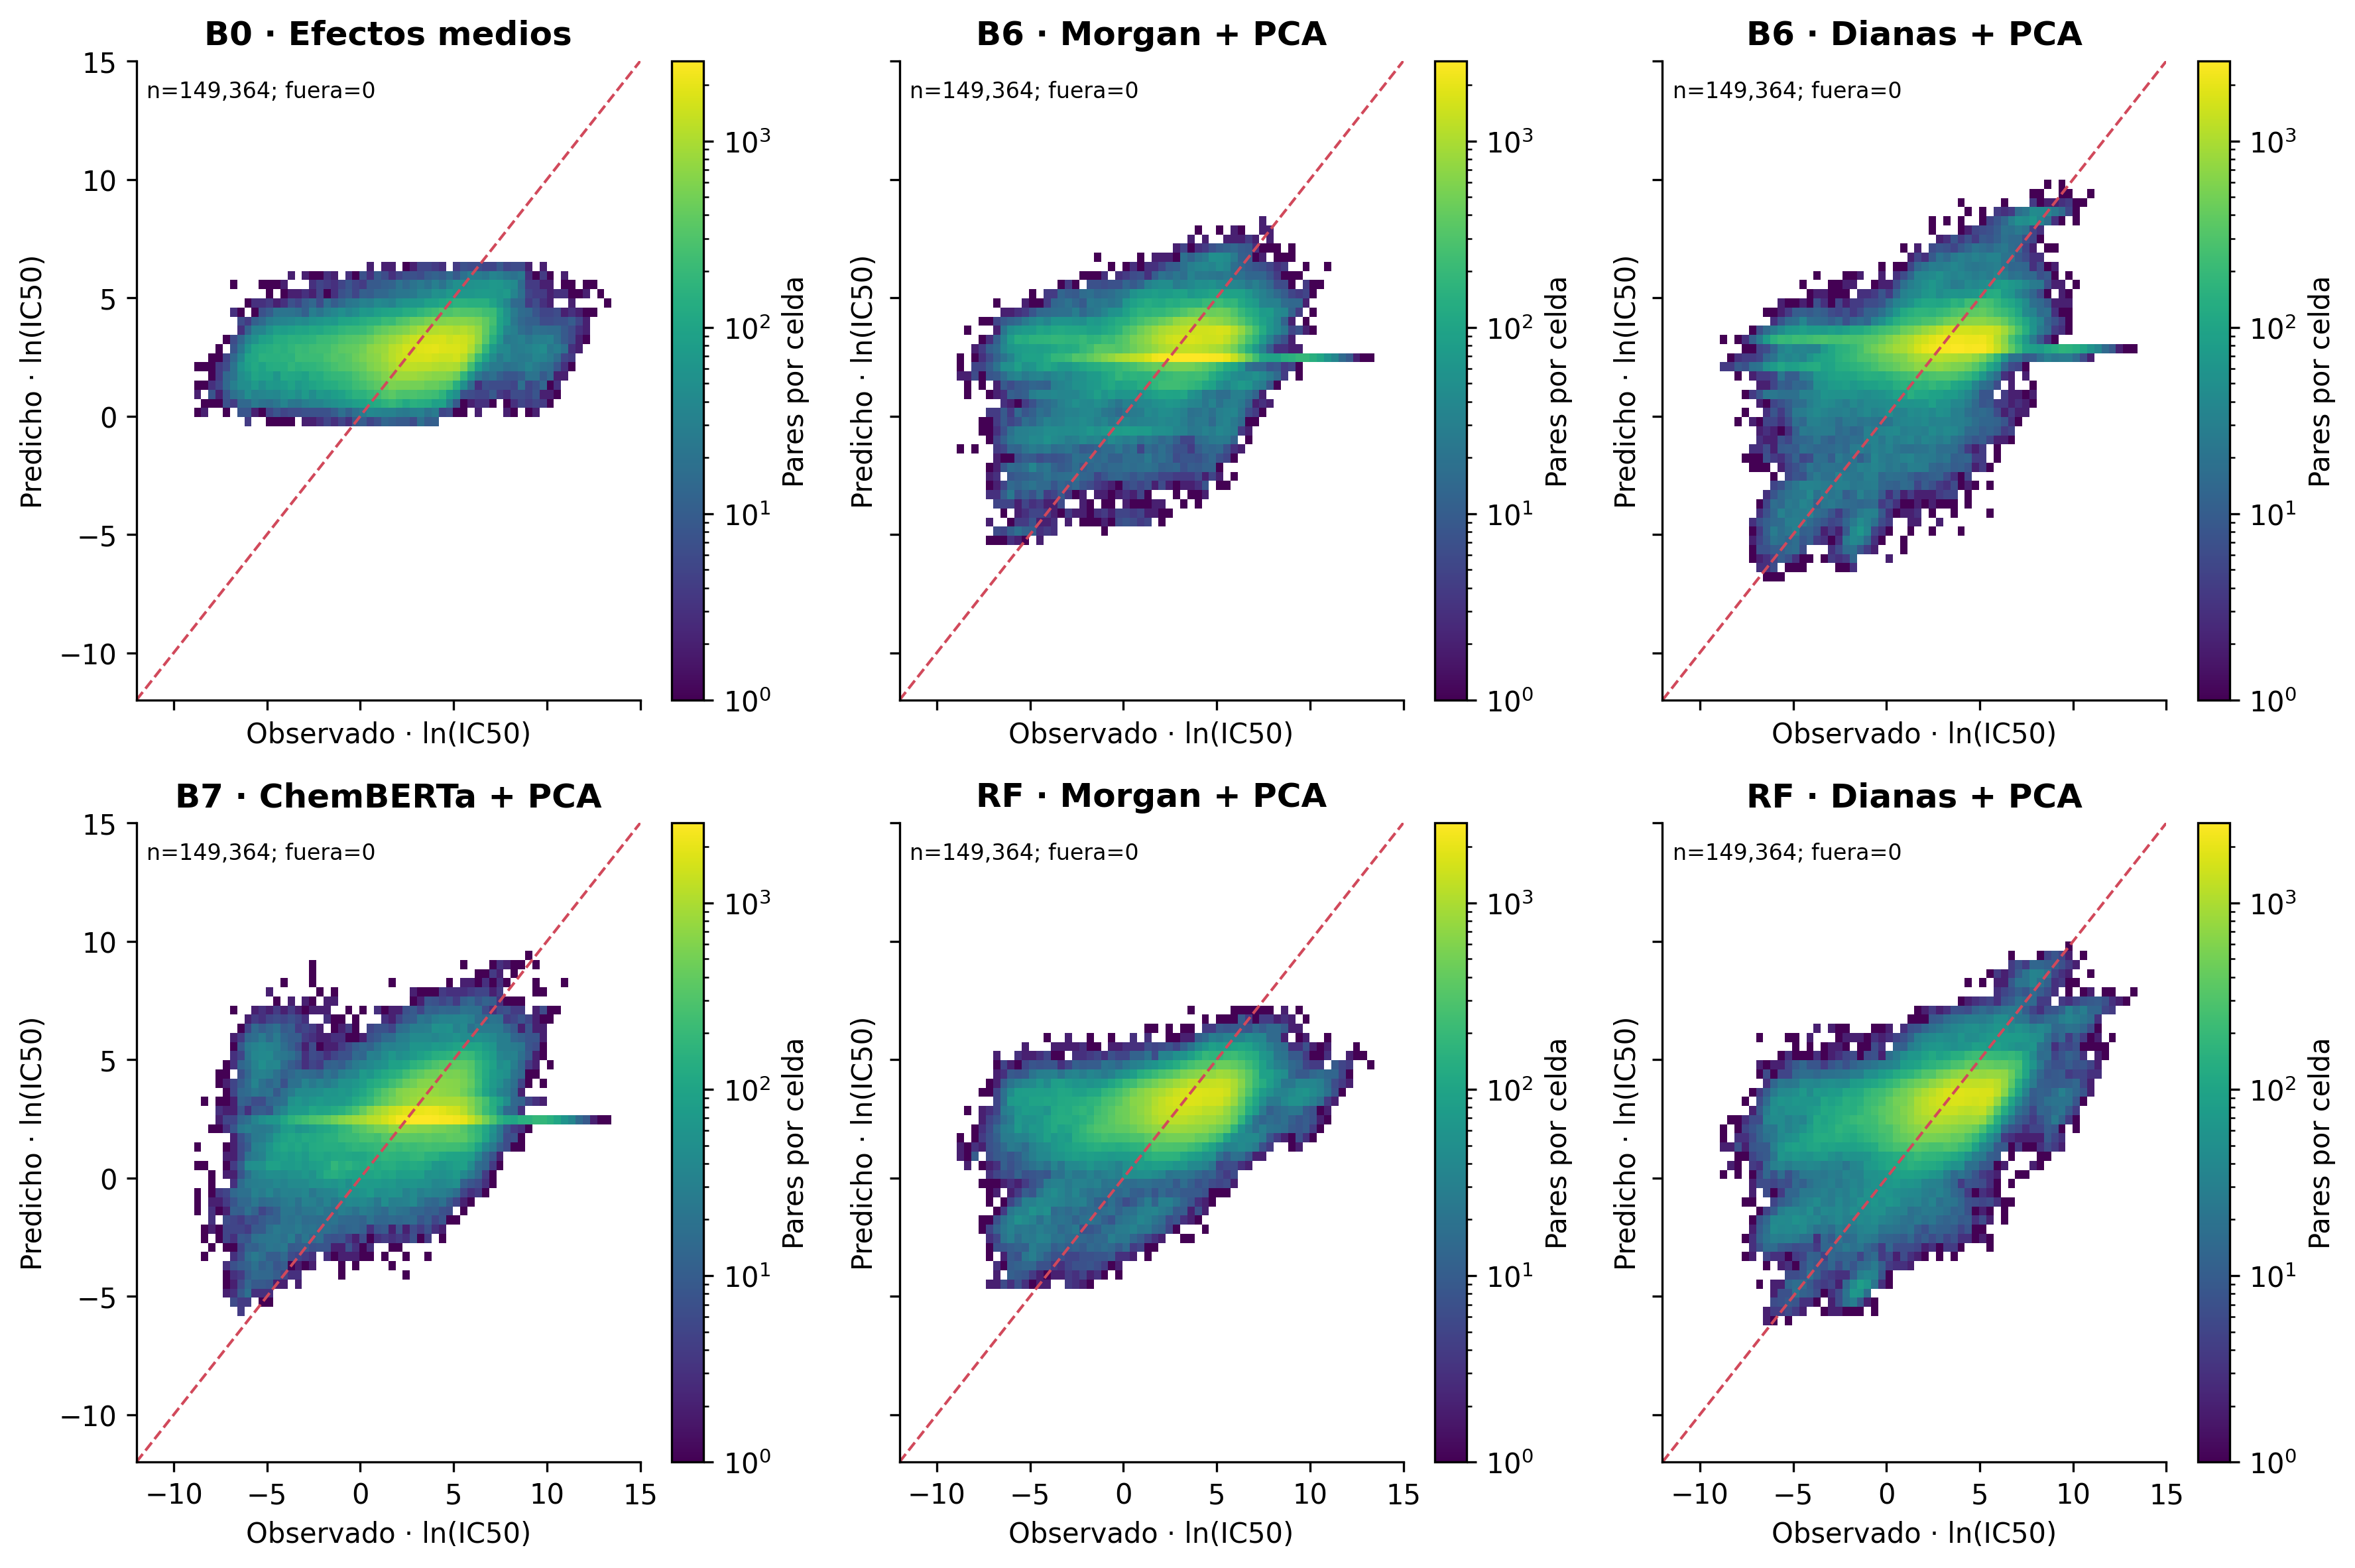

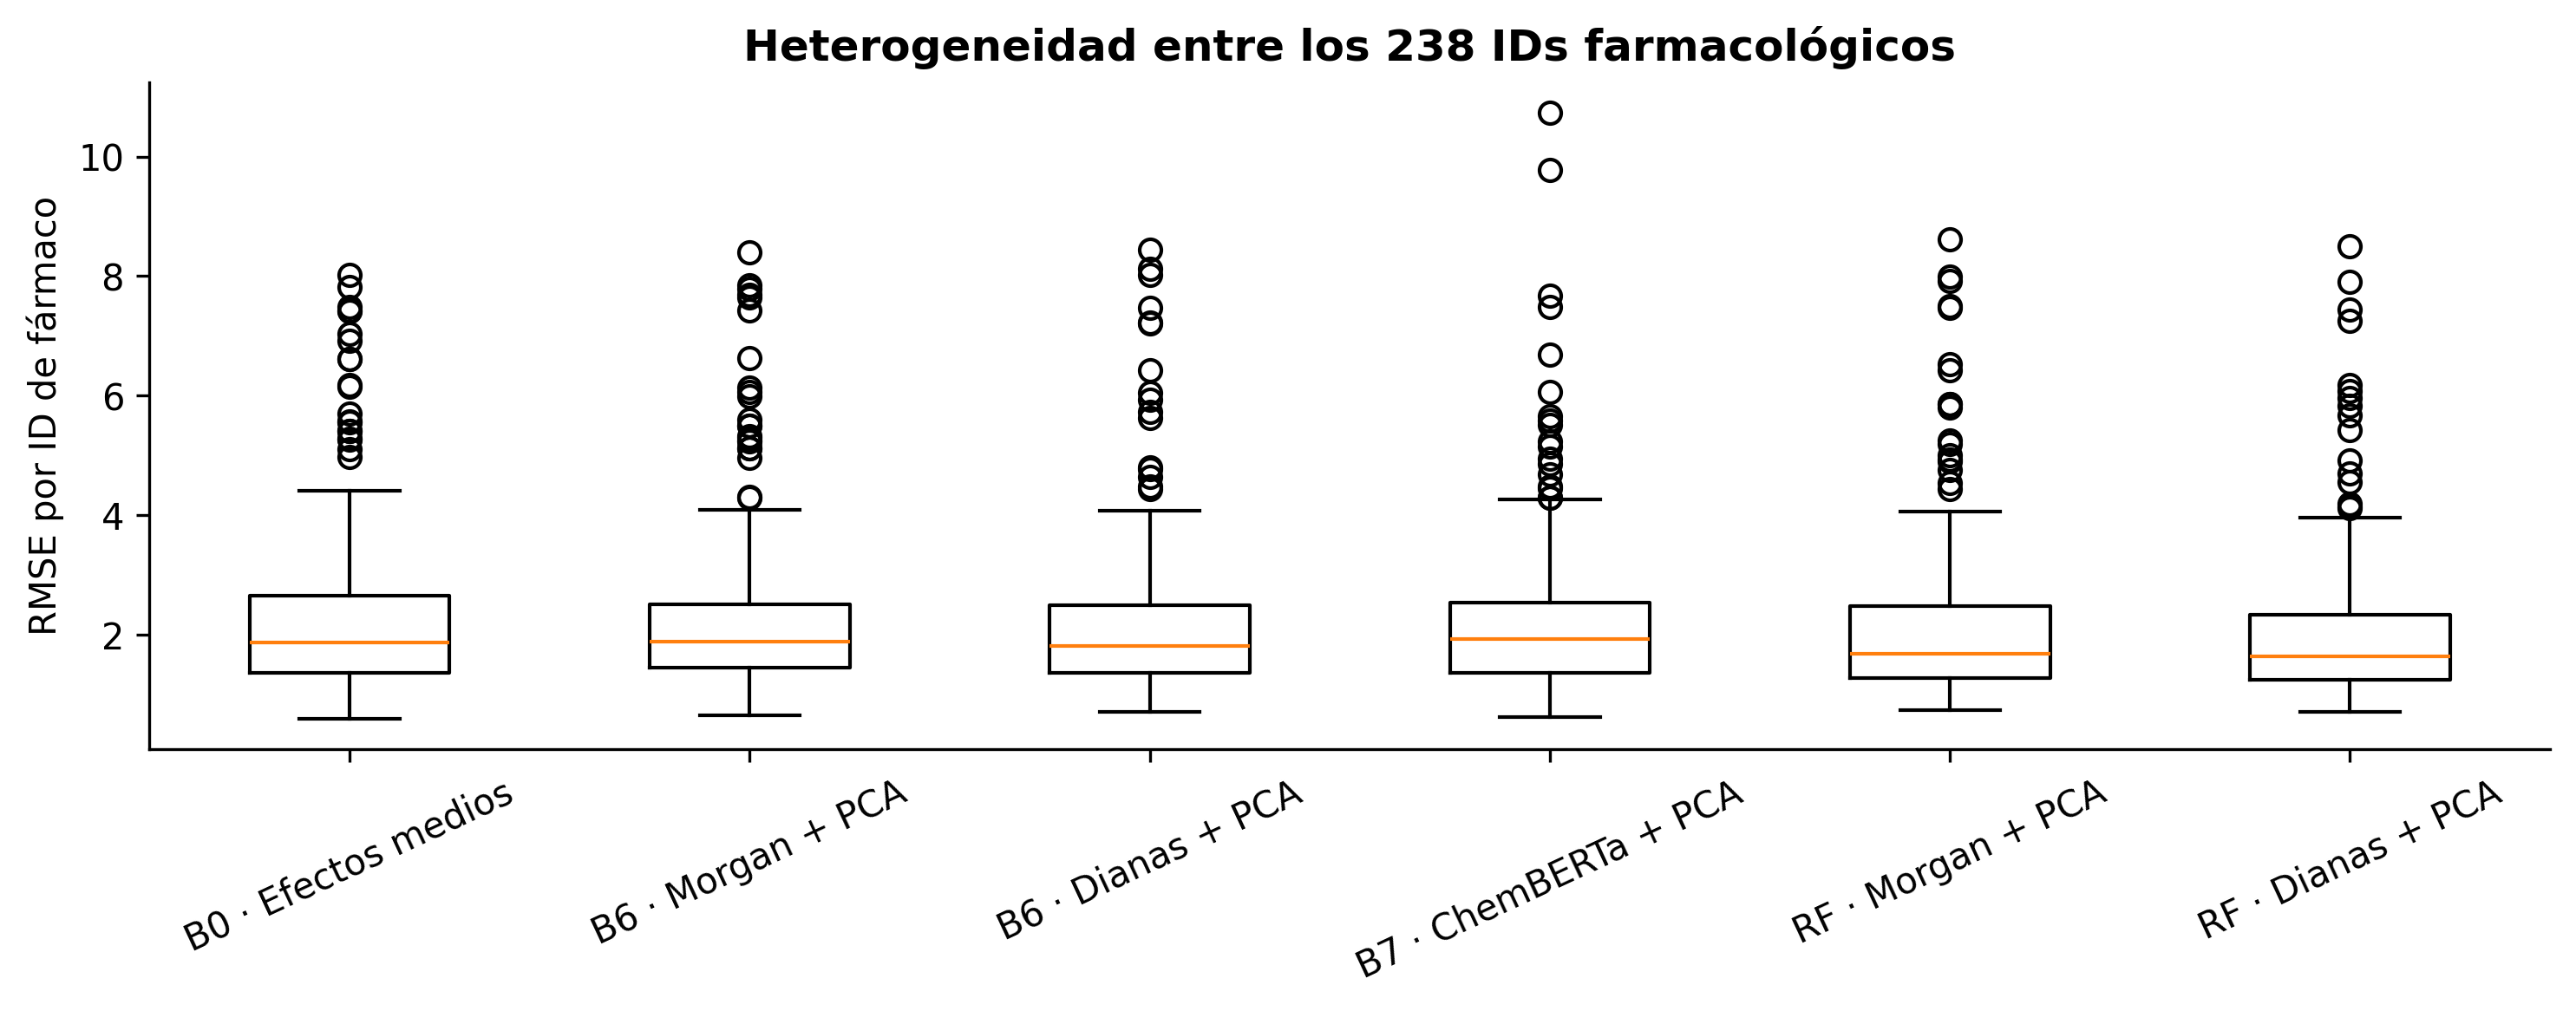

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8), sharex=True, sharey=True)
common_max = max(np.max(row["counts"]) for row in s["densities"])
for ax, row in zip(axes.flat, s["densities"]):
    edges = np.array(row["edges"])
    im = ax.pcolormesh(edges, edges, np.array(row["counts"]).T, norm=LogNorm(vmin=1, vmax=common_max), cmap="viridis")
    ax.plot([edges[0], edges[-1]], [edges[0], edges[-1]], "--", color="#d1495b", lw=1)
    ax.set(title=pretty_model(row["model"]), xlabel="Observado · ln(IC50)", ylabel="Predicho · ln(IC50)")
    ax.text(.02, .97, f"n={row['n']:,}; fuera={row['outside_plot']}", transform=ax.transAxes, va="top", fontsize=8)
    fig.colorbar(im, ax=ax, label="Pares por celda")
save(fig, "04_densidad_predicciones")
errors = pd.DataFrame(s["drug_errors"])
groups = [r.model for r in pd.DataFrame(s["pooled_test"]).itertuples()]
fig, ax = plt.subplots(figsize=(10, 4))
labels = errors.model.unique()
ax.boxplot([errors.loc[errors.model.eq(k), "rmse"] for k in labels], tick_labels=[pretty_model(k) for k in labels], showfliers=True)
ax.tick_params(axis="x", rotation=25)
ax.set(ylabel="RMSE por ID de fármaco", title="Heterogeneidad entre los 238 IDs farmacológicos")
save(fig, "05_error_por_farmaco")


## 3. Incertidumbre de la comparación
Bootstrap pareado por identidad química completa (2.000 remuestreos), manteniendo juntos los IDs alias y condicionado a los modelos ya ajustados. Una diferencia negativa favorece al candidato frente a B0; no mide variación por reentrenamiento.

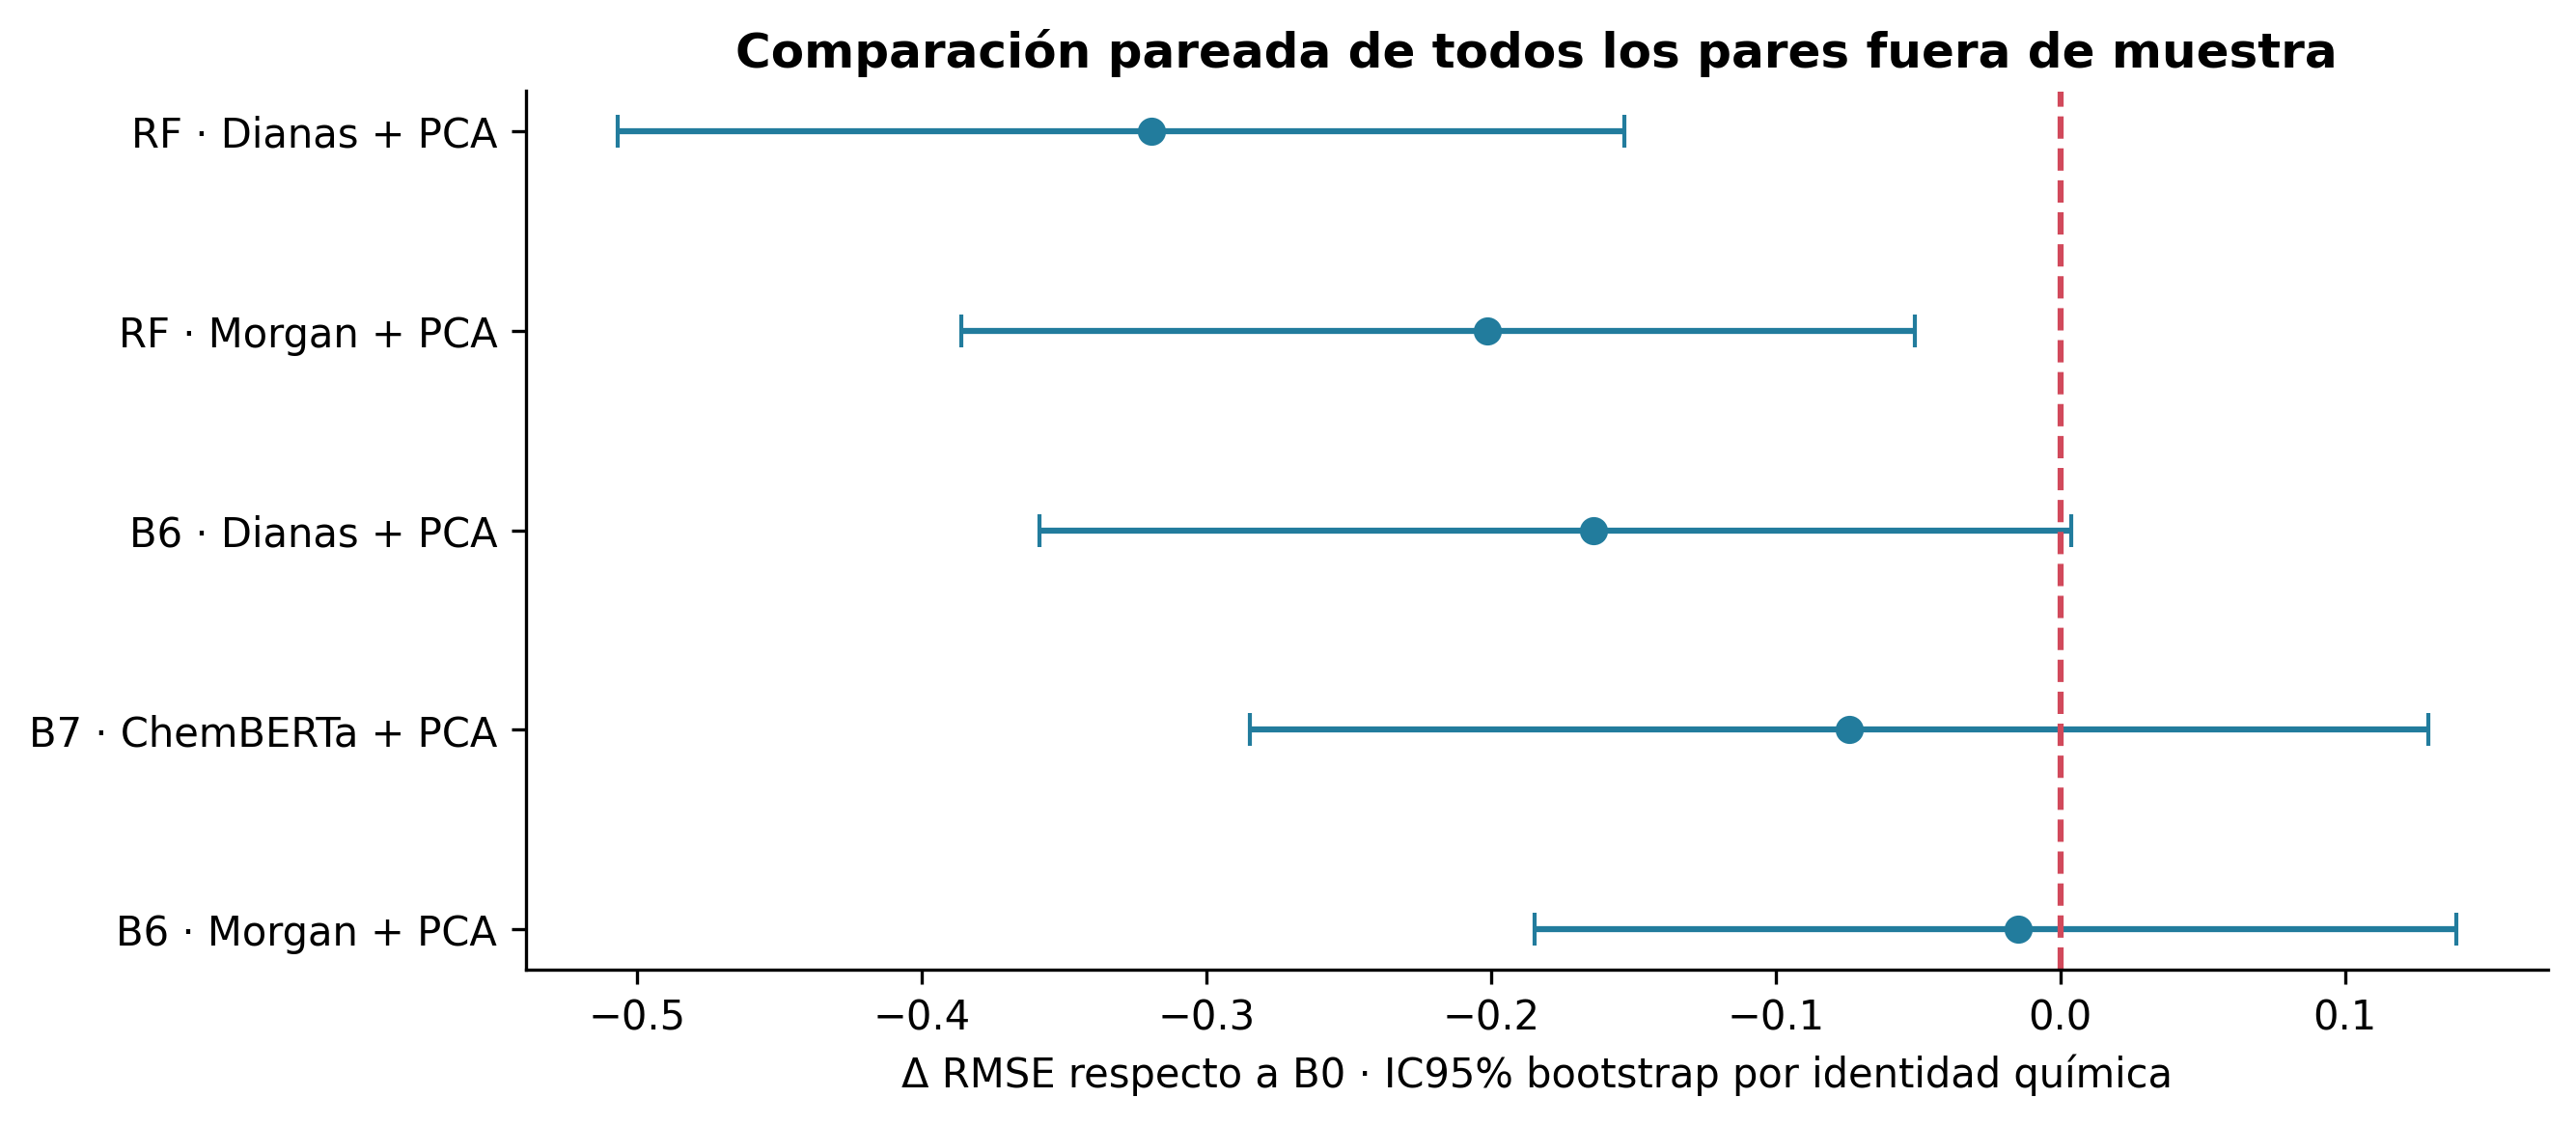

In [6]:
boot = pd.DataFrame(s["bootstrap"])
pooled = boot.loc[boot.case.eq("cold_drug_pooled")].sort_values("rmse_delta")
fig, ax = plt.subplots(figsize=(9, 4))
ax.errorbar(pooled.rmse_delta, pooled.model.map(pretty_model), xerr=np.vstack([pooled.rmse_delta-pooled.ci95_low, pooled.ci95_high-pooled.rmse_delta]), fmt="o", capsize=4, color="#227C9D")
ax.axvline(0, color="#d1495b", linestyle="--")
ax.invert_yaxis()
ax.set(xlabel="Δ RMSE respecto a B0 · IC95% bootstrap por identidad química", title="Comparación pareada de todos los pares fuera de muestra")
save(fig, "06_bootstrap")


## 4. Selección de Random Forest
Los cuatro candidatos se comparan usando solo validación. El test se calcula después de elegir el modelo.

,params,validation_rmse,bootstrap,max_features,min_samples_leaf,n_estimators,n_jobs,random_state,case,model
0,"{""bootstrap"": true, ""max_features"": ""sqrt"", ""m...",2.430309,True,sqrt,5,200,8,42,cold_drug_fold_0,RF · morgan_expression_pca
1,"{""bootstrap"": true, ""max_features"": ""sqrt"", ""m...",2.461589,True,sqrt,20,200,8,42,cold_drug_fold_0,RF · morgan_expression_pca
2,"{""bootstrap"": true, ""max_features"": 0.1, ""min_...",2.375879,True,0.1,5,200,8,42,cold_drug_fold_0,RF · morgan_expression_pca
3,"{""bootstrap"": true, ""max_features"": 0.1, ""min_...",2.435267,True,0.1,20,200,8,42,cold_drug_fold_0,RF · morgan_expression_pca
4,"{""bootstrap"": true, ""max_features"": ""sqrt"", ""m...",1.980500,True,sqrt,5,200,8,42,cold_drug_fold_0,RF · targets_expression_pca
5,"{""bootstrap"": true, ""max_features"": ""sqrt"", ""m...",2.024503,True,sqrt,20,200,8,42,cold_drug_fold_0,RF · targets_expression_pca
6,"{""bootstrap"": true, ""max_features"": 0.1, ""min_...",1.917146,True,0.1,5,200,8,42,cold_drug_fold_0,RF · targets_expression_pca
7,"{""bootstrap"": true, ""max_features"": 0.1, ""min_...",1.937358,True,0.1,20,200,8,42,cold_drug_fold_0,RF · targets_expression_pca
8,"{""bootstrap"": true, ""max_features"": ""sqrt"", ""m...",2.372388,True,sqrt,5,200,8,42,cold_drug_fold_1,RF · morgan_expression_pca
9,"{""bootstrap"": true, ""max_features"": ""sqrt"", ""m...",2.412451,True,sqrt,20,200,8,42,cold_drug_fold_1,RF · morgan_expression_pca


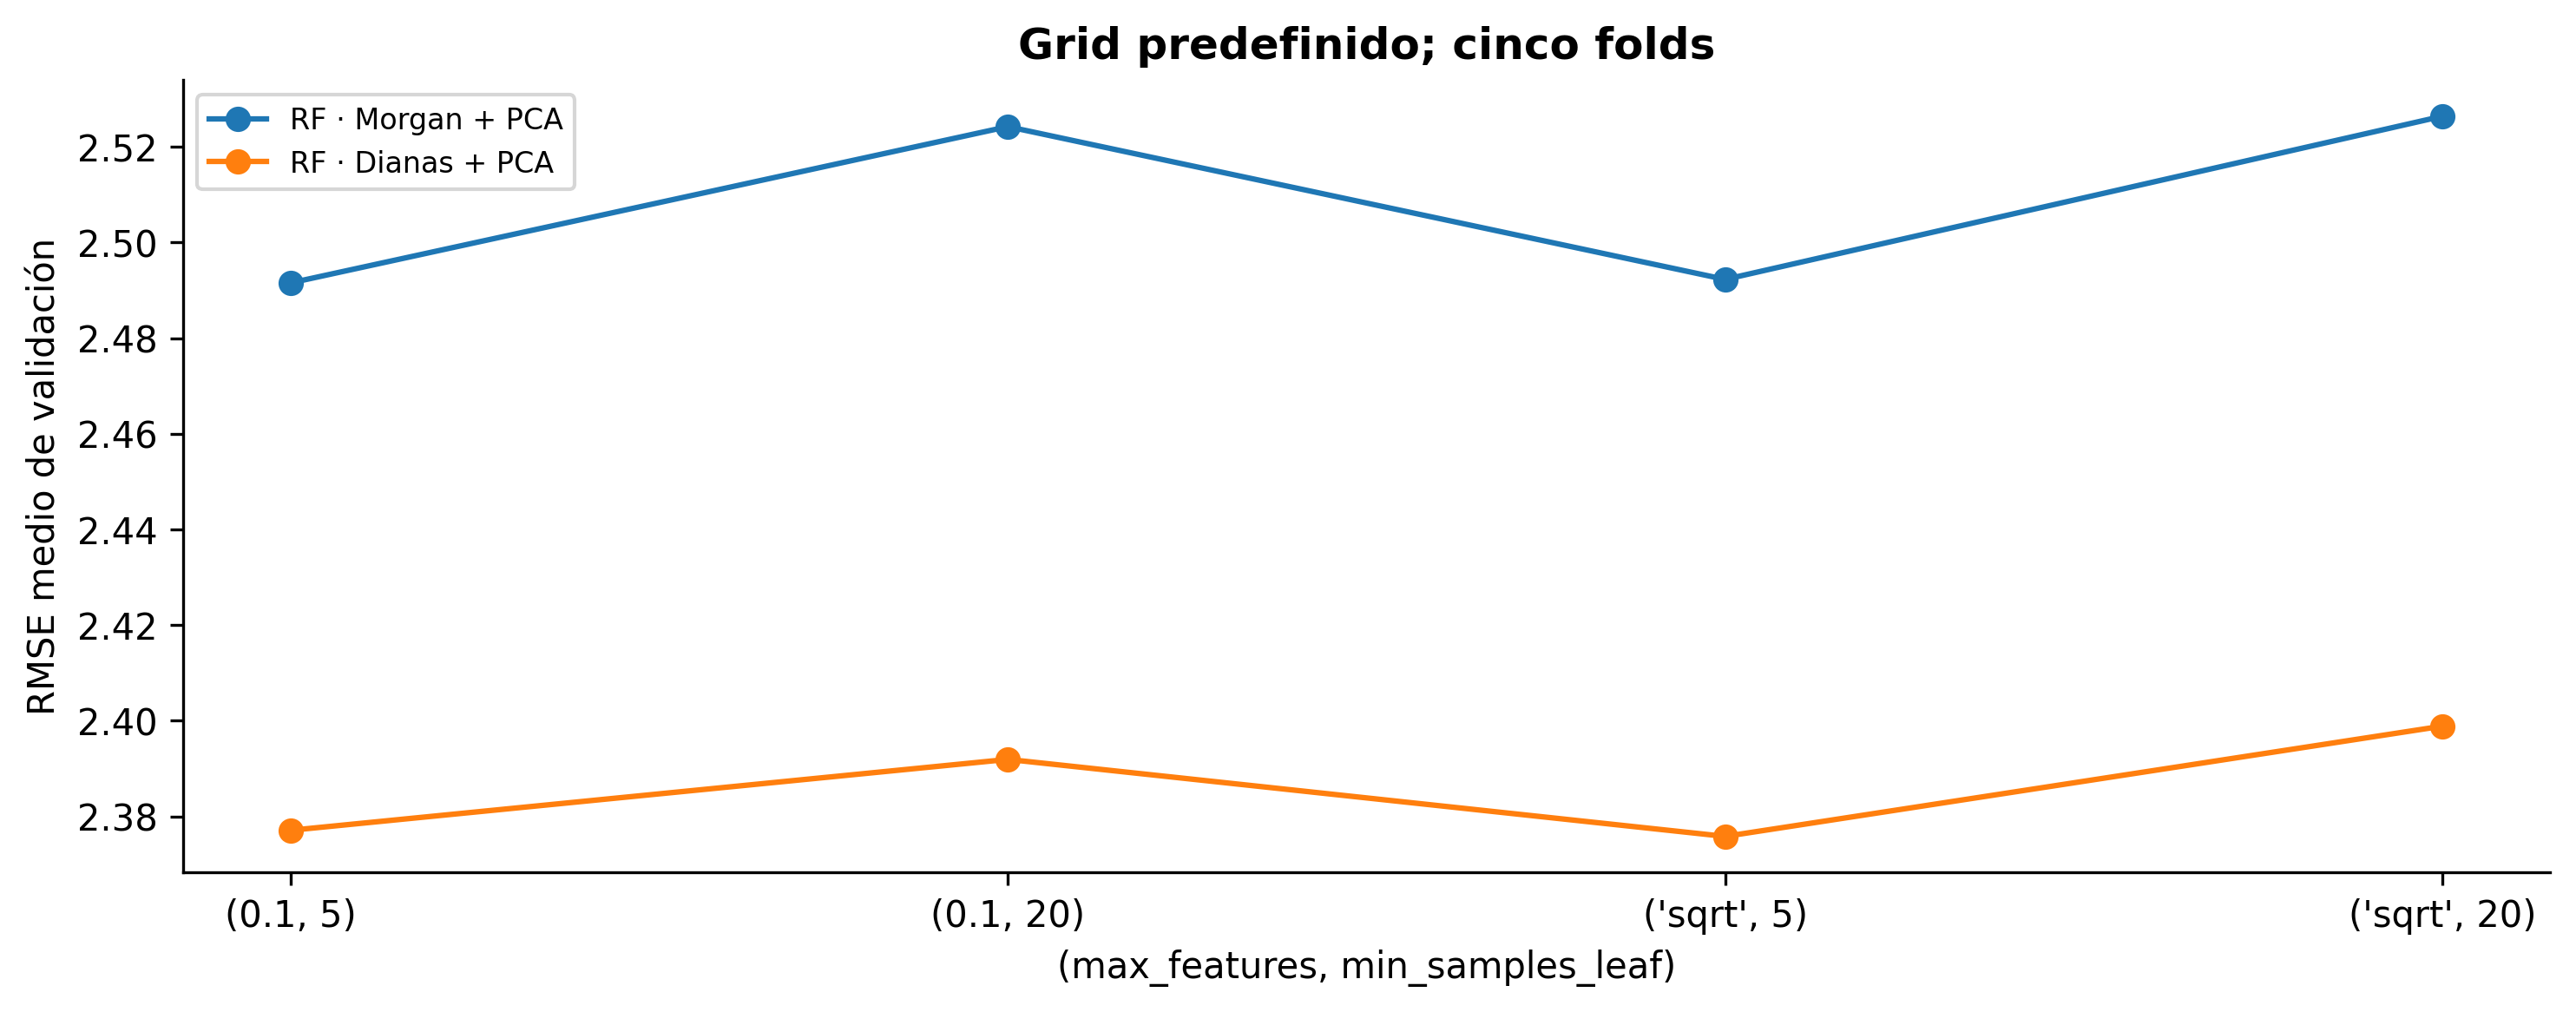

In [7]:
grid = pd.DataFrame(s["rf_candidates"])
display(grid.head(12))
fig, ax = plt.subplots(figsize=(10, 4))
for name, rows in grid.loc[grid.case.str.fullmatch(r"cold_drug_fold_\d")].groupby("model"):
    column = "validation_rmse" if "validation_rmse" in rows else "rmse"
    values = rows.groupby(["max_features", "min_samples_leaf"], dropna=False)[column].mean()
    ax.plot([str(k) for k in values.index], values.values, "o-", label=pretty_model(name))
ax.set(xlabel="(max_features, min_samples_leaf)", ylabel="RMSE medio de validación", title="Grid predefinido; cinco folds")
ax.legend(fontsize=8)
save(fig, "07_seleccion_rf")


## Evolución del ajuste XGBoost
RMSE de validación por iteración; el punto marca la iteración seleccionada. Se permite un máximo de 700 iteraciones y una paciencia de 40; el ajuste puede terminar por cualquiera de esos límites. Las curvas pueden continuar después de la mejor iteración durante la paciencia. No se utiliza el test para decidir dónde detener el entrenamiento.

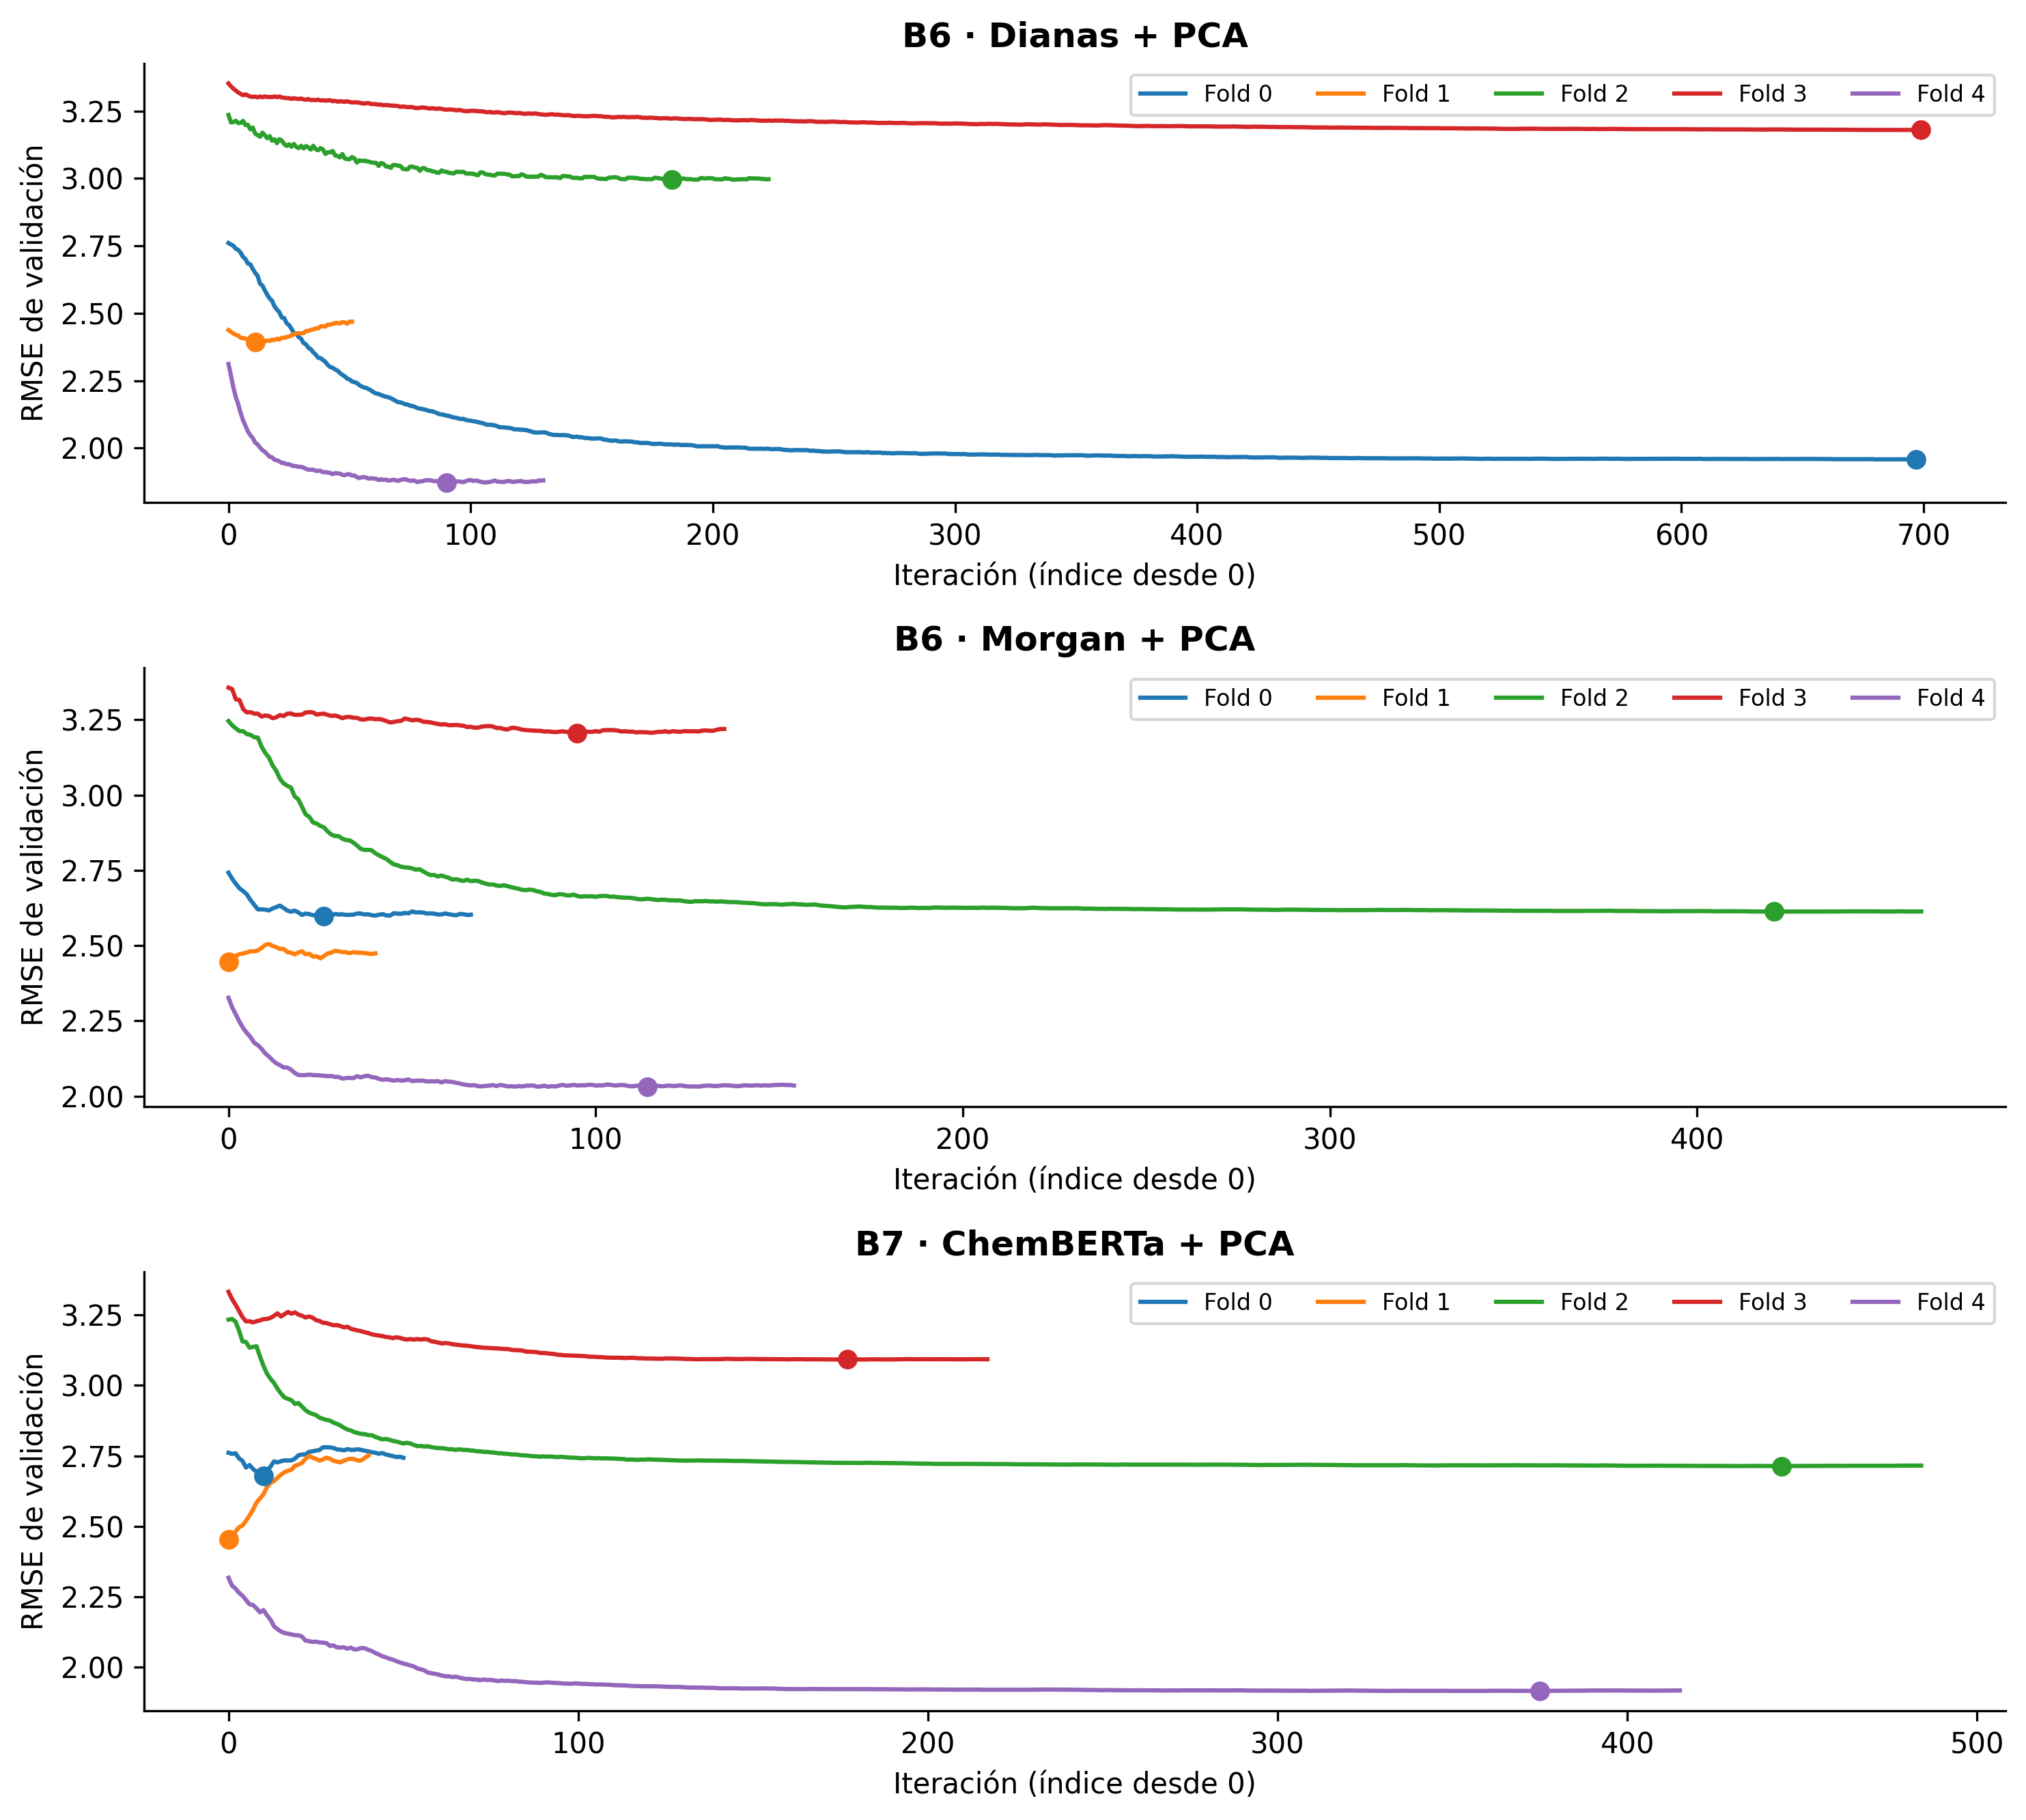

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(10, 9))
specs = [("B6", "targets_expression_pca"), ("B6", "morgan_expression_pca"), ("B7", "pretrained_drug_expression_pca")]
for ax, (stage, model) in zip(axes, specs):
    for history in s["learning_histories"]:
        if history["stage"] != stage or history["model"] != model or not pd.Series([history["case"]]).str.fullmatch(r"cold_drug_fold_\d").iloc[0]:
            continue
        values = history["validation_rmse"]
        chosen = history["best_iteration"]
        line, = ax.plot(range(len(values)), values, label="Fold " + history["case"].rsplit("_", 1)[1])
        ax.scatter([chosen], [values[chosen]], color=line.get_color(), s=35, zorder=3)
    ax.set(title=pretty_model(stage + " · " + model), xlabel="Iteración (índice desde 0)", ylabel="RMSE de validación")
    ax.legend(fontsize=8, ncol=5)
save(fig, "07b_validacion_xgboost")


## 5. Transferencia GDSC→PRISM
Mapeo químico estricto: 44 coincidencias completas de InChIKey y dos coincidencias inequívocas por conectividad; estas últimas no confirman identidad estereoquímica. Se muestran AUC publicada, AUC armonizada y AUC publicada sobre exactamente los mismos pares elegibles para armonización. El ajuste 3PL exige soporte de dosis en log10(µM) [-1,9; 0,9] y no extrapola. Las definiciones de AUC son distintas: se debe comparar cada modelo con B0 dentro del mismo endpoint. Cambiar la ventana no iguala el tiempo de exposición ni la biología del ensayo.

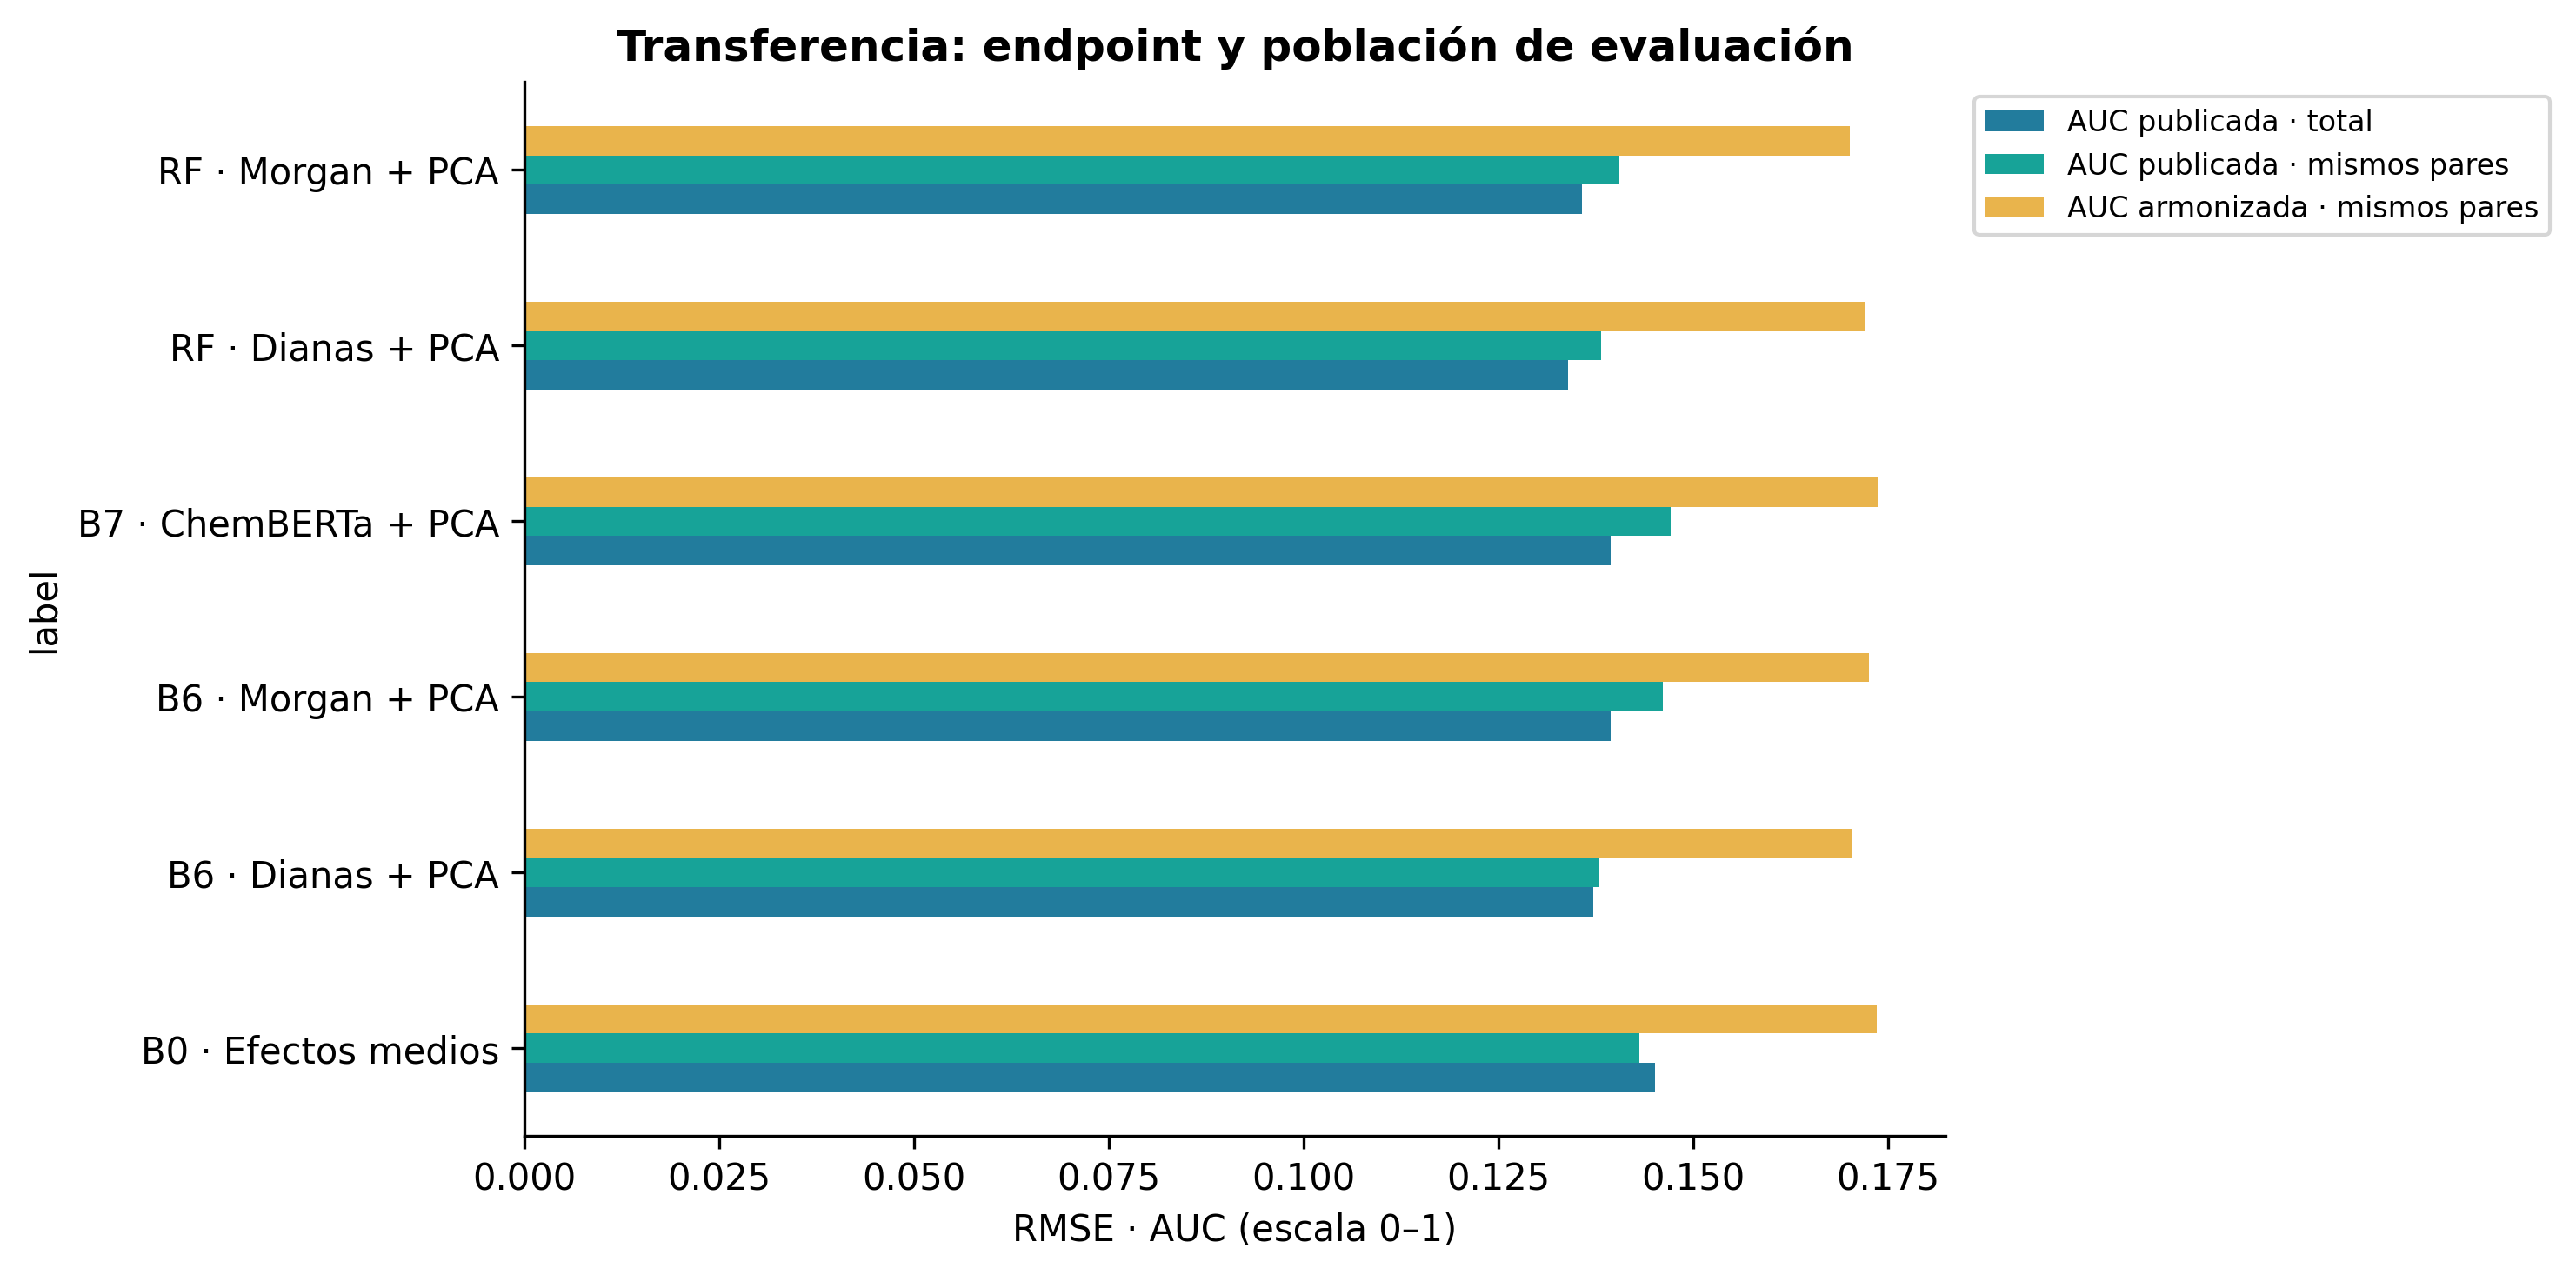

,case,label,n_rows,rmse,spearman
90,harmonized_transfer,B0 · Efectos medios,10785,0.173554,0.255715
92,harmonized_transfer,B6 · Morgan + PCA,10785,0.172490,0.293865
94,harmonized_transfer,B6 · Dianas + PCA,10785,0.170294,0.299268
96,harmonized_transfer,B7 · ChemBERTa + PCA,10785,0.173645,0.267623
98,harmonized_transfer,RF · Morgan + PCA,10785,0.170038,0.301056
100,harmonized_transfer,RF · Dianas + PCA,10785,0.171932,0.271020
108,matched_published_transfer,B0 · Efectos medios,10785,0.143046,0.213531
110,matched_published_transfer,B6 · Morgan + PCA,10785,0.146036,0.217352
112,matched_published_transfer,B6 · Dianas + PCA,10785,0.137971,0.259513
114,matched_published_transfer,B7 · ChemBERTa + PCA,10785,0.147031,0.234130


,Ensayo,Subconjunto,Pares,Células,Fármacos
0,gdsc2,train,9202,616,23
1,gdsc2,validation,1551,569,23
2,prism,test,10785,335,38


study,gdsc2,prism
status,,
constant_fallback,1352.0,4374.0
fit_failed,470.0,661.0
flat,4.0,1.0
insufficient_dose_coverage,8524.0,2700.0
sigmoid_3pl,9397.0,6410.0
too_few_doses,0.0,54.0


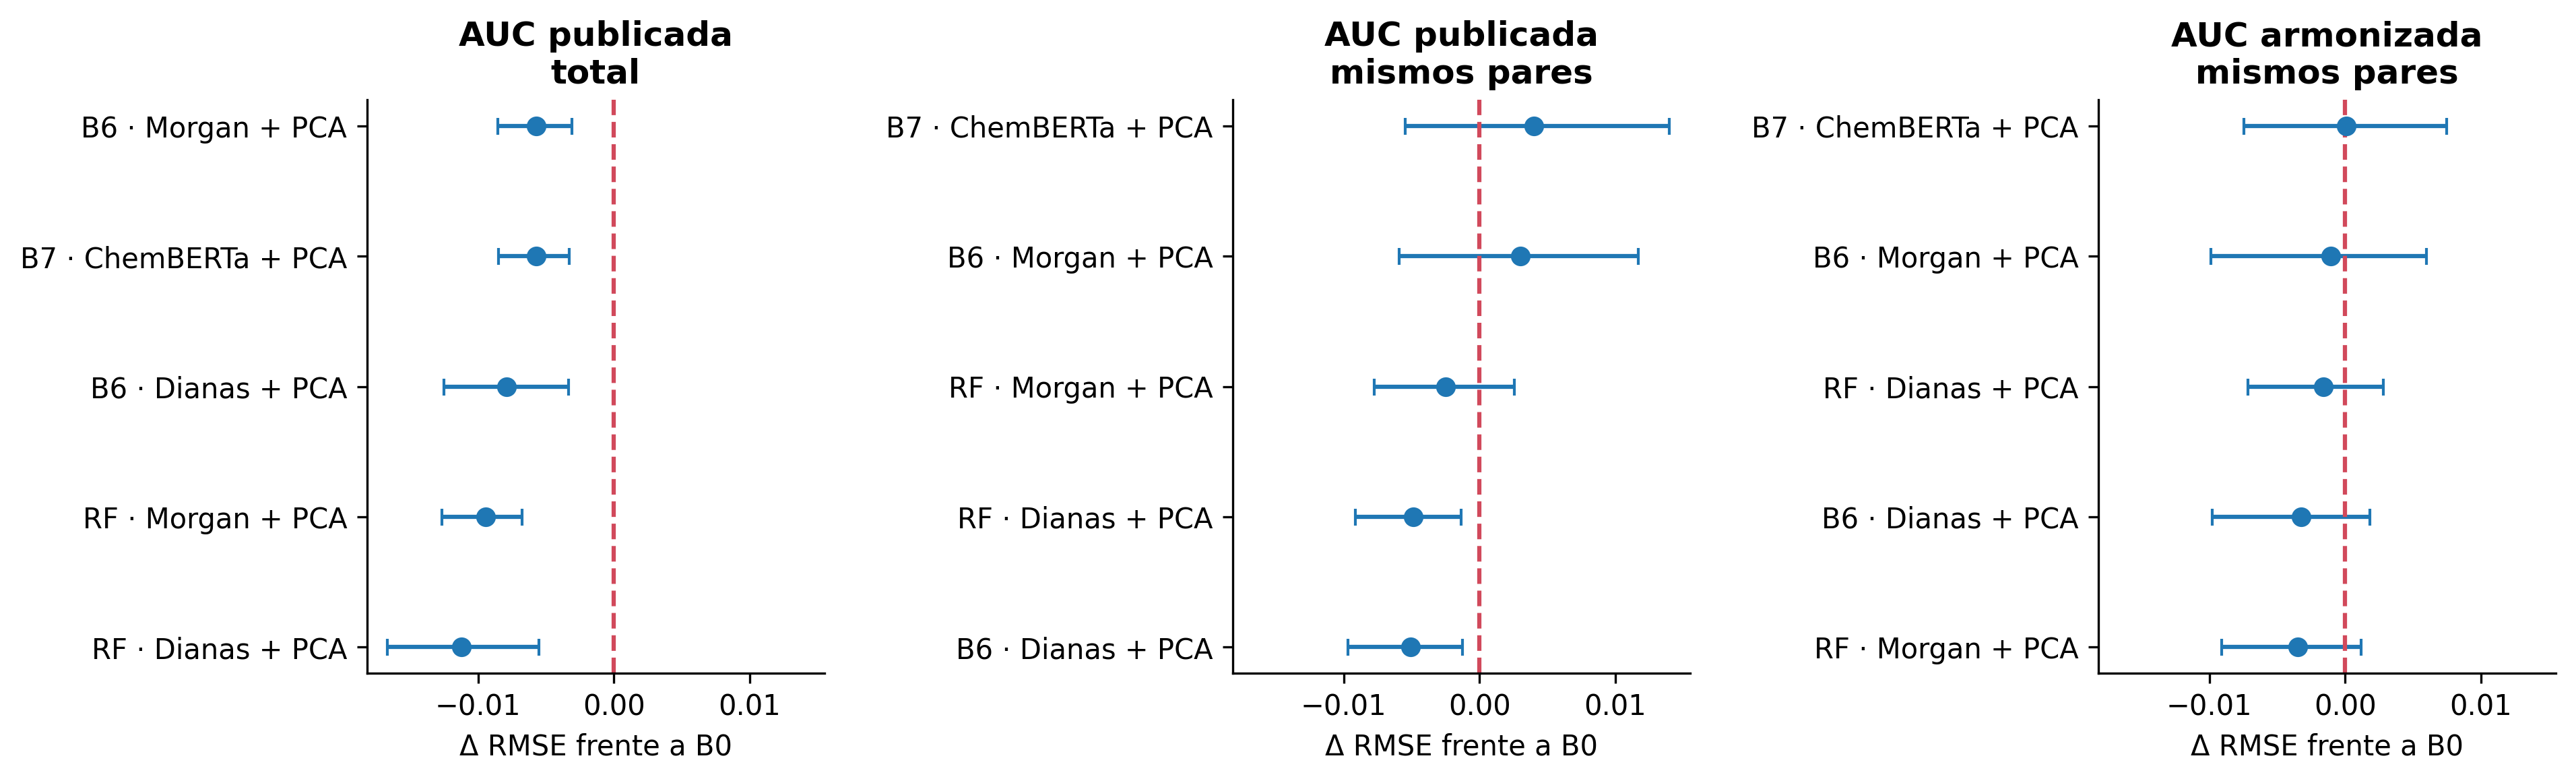

In [9]:
transfer = metrics.loc[metrics.case.str.endswith("transfer") & metrics.subset.eq("test")].copy()
transfer["label"] = label(transfer)
table = transfer.pivot(index="label", columns="case", values="rmse").reindex(columns=CASE_ORDER).rename(columns=CASE_LABELS)
fig, ax = plt.subplots(figsize=(10, 5))
table.plot.barh(ax=ax, color=["#227C9D", "#17A398", "#E9B44C"])
ax.set(xlabel="RMSE · AUC (escala 0–1)", title="Transferencia: endpoint y población de evaluación")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
save(fig, "08_transferencia")
display(transfer[["case", "label", "n_rows", "rmse", "spearman"]] if "n_rows" in transfer else transfer[["case", "label", "rmse", "spearman"]])
display(pd.DataFrame(s["harmonization"]["counts"]).rename(columns={
    "study": "Ensayo", "split": "Subconjunto", "n_pairs": "Pares", "n_cells": "Células", "n_drugs": "Fármacos"}))
display(pd.DataFrame(s["harmonization"]["fit_status"]).pivot(index="status", columns="study", values="n").fillna(0))
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True)
for ax, case in zip(axes, CASE_ORDER):
    rows = boot.loc[boot.case.eq(case)]
    rows = rows.sort_values("rmse_delta")
    ax.errorbar(rows.rmse_delta, rows.model.map(pretty_model), xerr=np.vstack([rows.rmse_delta-rows.ci95_low, rows.ci95_high-rows.rmse_delta]), fmt="o", capsize=3)
    ax.axvline(0, linestyle="--", color="#d1495b")
    ax.set(title=CASE_LABELS[case].replace(" · ", "\n"), xlabel="Δ RMSE frente a B0")
save(fig, "09_bootstrap_transferencia")


## 6. Calibración independiente
Se reservan entidades de entrenamiento exclusivamente para calibración; nunca se ajusta el radio con test. Se evalúan intervalos por máximo residual de entidad, crudos y con transformación afín ajustada en validación. La línea del 90% es un objetivo, no una garantía bajo cambio de distribución.

,stage,model,variant,split_name,method,alpha,group_column,n_calibration_groups,radius,status,...,n_rows,n_groups,row_coverage,whole_group_coverage,mean_width,rmse,bias_pred_minus_true,diagnostic_intercept,diagnostic_slope,case
0,B6,morgan_expression_pca,standard,cold_drug,raw,0.1,chemical_id,21,9.928181,finite,...,30014,46,1.000000,1.000000,19.856362,1.978552,-0.374563,0.244367,1.045833,cold_drug_fold_0_calibration
1,B6,morgan_expression_pca,standard,cold_drug,affine_validation,0.1,chemical_id,21,10.593397,finite,...,30014,46,1.000000,1.000000,21.186793,1.961027,-0.011929,-0.881546,1.278924,cold_drug_fold_0_calibration
2,B6,targets_expression_pca,standard,cold_drug,raw,0.1,chemical_id,21,10.985131,finite,...,30014,46,1.000000,1.000000,21.970262,2.252853,-0.183324,1.604369,0.531302,cold_drug_fold_0_calibration
3,B6,targets_expression_pca,standard,cold_drug,affine_validation,0.1,chemical_id,21,11.390115,finite,...,30014,46,1.000000,1.000000,22.780230,2.150588,0.130517,1.207278,0.600150,cold_drug_fold_0_calibration
4,B6,morgan_expression_pca,standard,cold_drug,raw,0.1,chemical_id,21,9.977674,finite,...,30361,46,0.999934,0.978261,19.955348,2.681002,-0.488818,-6.498148,3.623400,cold_drug_fold_1_calibration
5,B6,morgan_expression_pca,standard,cold_drug,affine_validation,0.1,chemical_id,21,10.133944,finite,...,30361,46,0.999967,0.978261,20.267889,2.657488,-0.329225,-7.378390,3.730372,cold_drug_fold_1_calibration
6,B6,targets_expression_pca,standard,cold_drug,raw,0.1,chemical_id,21,9.882850,finite,...,30361,46,0.999967,0.978261,19.765700,2.613835,-0.331927,-12.126944,5.417701,cold_drug_fold_1_calibration
7,B6,targets_expression_pca,standard,cold_drug,affine_validation,0.1,chemical_id,21,10.003132,finite,...,30361,46,0.999967,0.978261,20.006264,2.623877,-0.246206,-17.963420,7.266353,cold_drug_fold_1_calibration
8,B6,morgan_expression_pca,standard,cold_drug,raw,0.1,chemical_id,21,9.415700,finite,...,30761,46,0.999902,0.978261,18.831399,2.419306,0.284682,1.178843,0.532034,cold_drug_fold_2_calibration
9,B6,morgan_expression_pca,standard,cold_drug,affine_validation,0.1,chemical_id,21,8.586661,finite,...,30761,46,0.999902,0.978261,17.173322,2.444519,-0.488248,1.567643,0.541559,cold_drug_fold_2_calibration


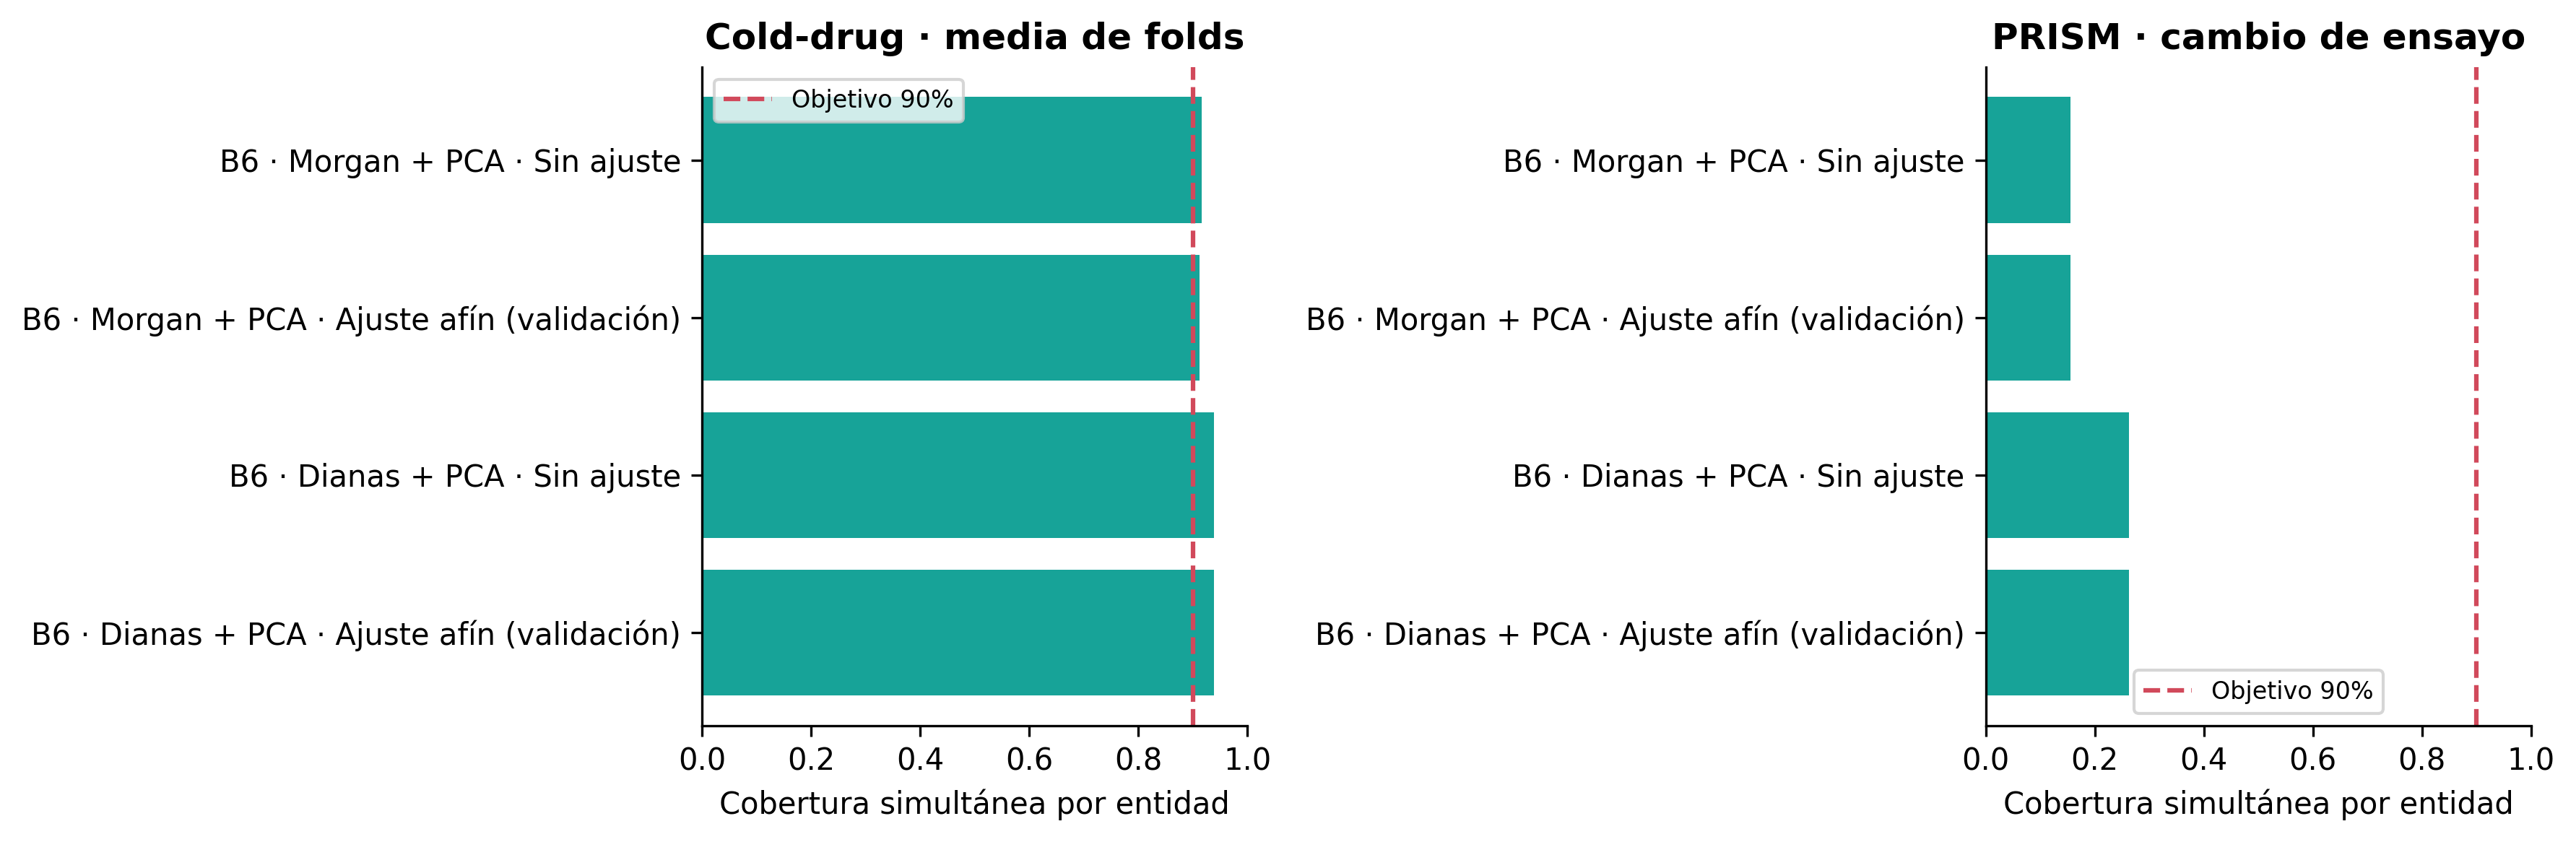

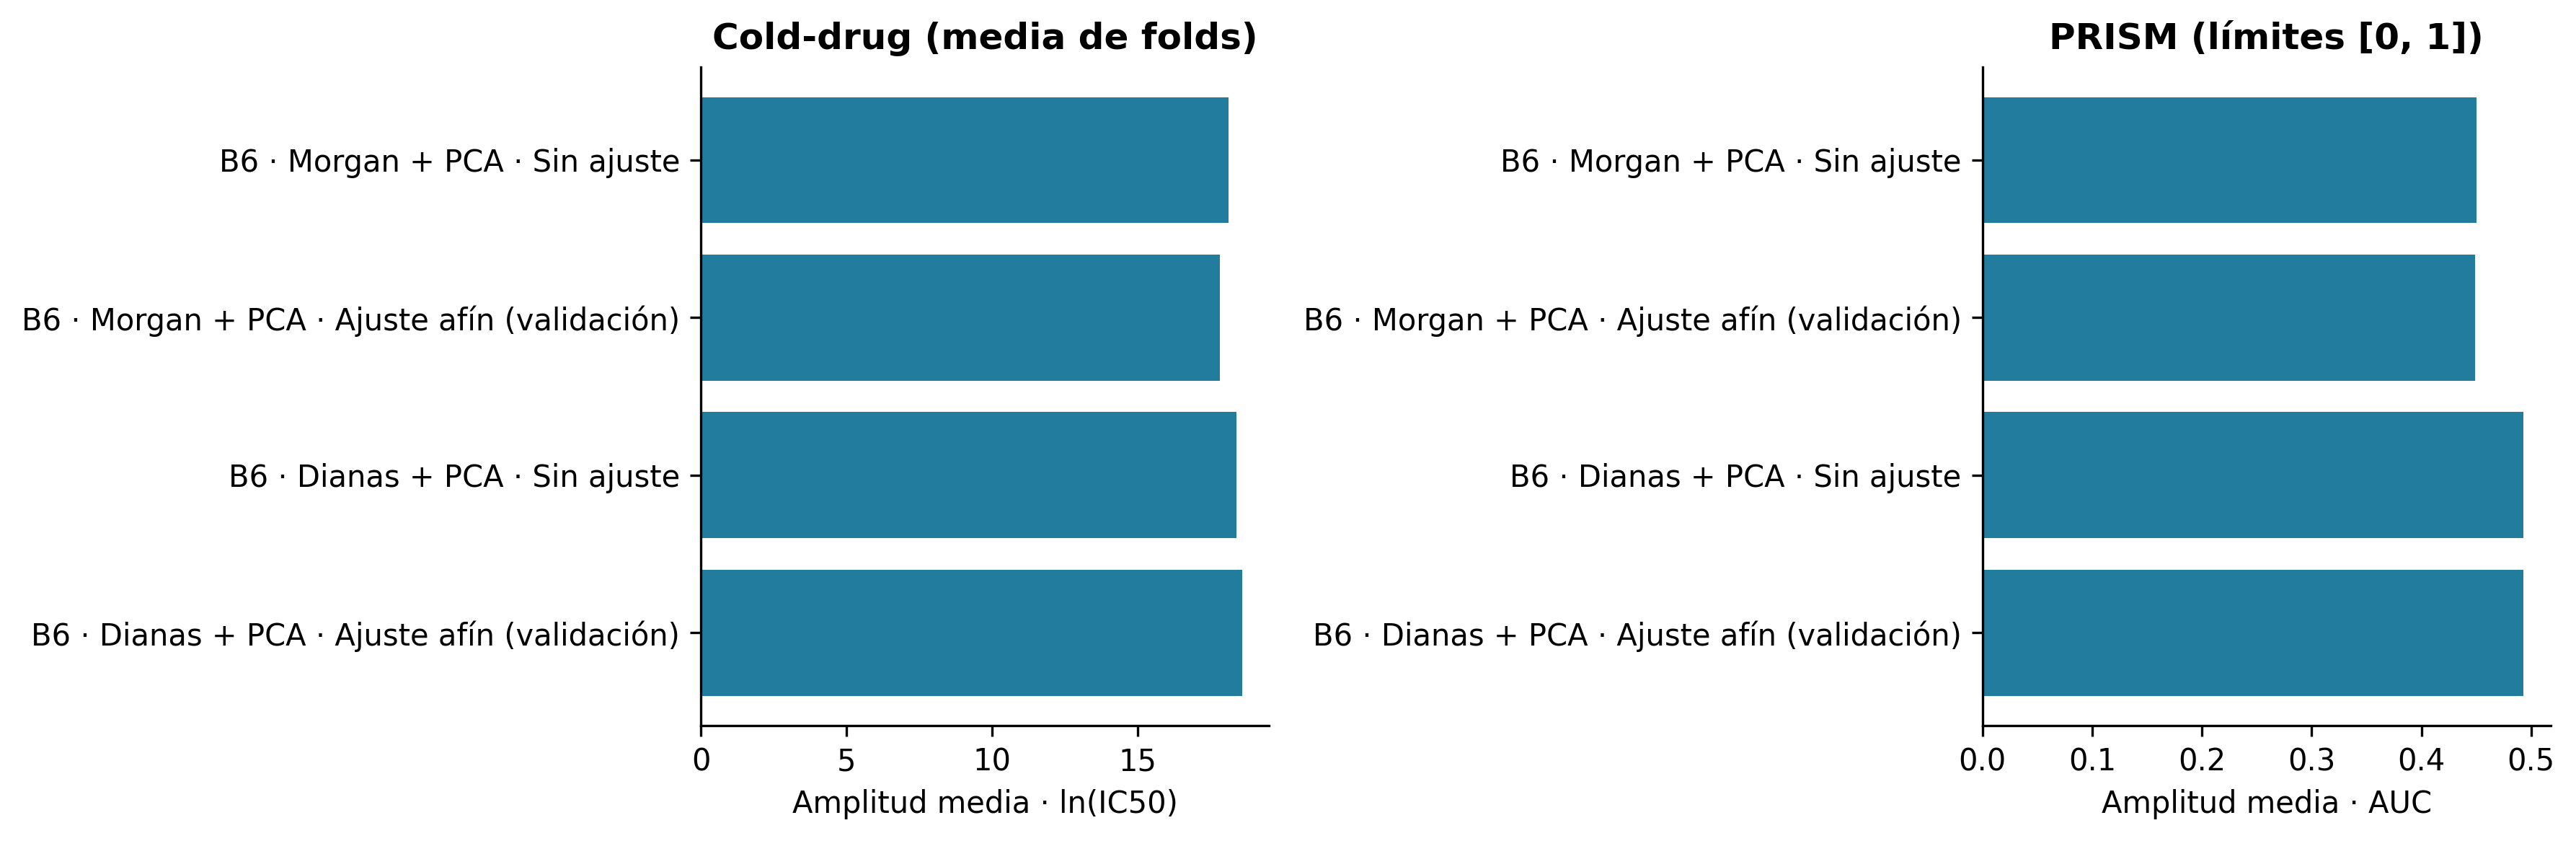

In [10]:
cal = pd.DataFrame(s["calibration"])
display(cal)
coverage_column = "whole_group_coverage"
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, transfer_only in zip(axes, (False, True)):
    rows = cal.loc[cal.case.str.contains("transfer").eq(transfer_only)].copy()
    rows["label"] = label(rows) + " · " + rows.method.map(METHOD_LABELS)
    column = coverage_column
    grouped = rows.groupby("label")[column].mean()
    ax.barh(grouped.index, grouped.values, color="#17A398")
    ax.axvline(.9, color="#d1495b", linestyle="--", label="Objetivo 90%")
    ax.set(xlim=(0, 1), xlabel="Cobertura simultánea por entidad", title="PRISM · cambio de ensayo" if transfer_only else "Cold-drug · media de folds")
    ax.legend(fontsize=8)
save(fig, "10_cobertura")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, transfer_only in zip(axes, (False, True)):
    rows = cal.loc[cal.case.str.contains("transfer").eq(transfer_only)].copy()
    rows["label"] = label(rows) + " · " + rows.method.map(METHOD_LABELS)
    widths = rows.groupby("label").mean_width.mean()
    ax.barh(widths.index, widths.values, color="#227C9D")
    ax.set(xlabel="Amplitud media · AUC" if transfer_only else "Amplitud media · ln(IC50)", title="PRISM (límites [0, 1])" if transfer_only else "Cold-drug (media de folds)")
save(fig, "11_radios")


## 7. Procedencia y aceptación
El informe corresponde a una ejecución nueva: seis modelos × ocho escenarios, más doce ajustes independientes para calibración. Los 60 modelos recargados reproducen sus predicciones. Los hashes de entrada y el entorno están congelados. La verificación del directorio completo se ejecuta con `python -m mcdrp.experiments.stable_v1 verify --output ...`. Los archivos externos grandes son necesarios para reentrenar, no para regenerar estas gráficas.

In [11]:
display(pd.DataFrame(s["reproduction"]))
display(pd.DataFrame(s["case_reproduction"]))
print("Referencia de versión:", s["reference_status"])
print("Comparación histórica:", s["legacy_comparison_role"])
display(pd.DataFrame(s["legacy_checkpoint_comparison"]))
display(pd.DataFrame(s["numerical_validation"]))
display(pd.DataFrame.from_dict(s["out_of_fold_coverage"], orient="index", columns=["pares_test_unicos"]))
display(pd.DataFrame.from_dict(s["config"]["inputs"], orient="index"))
display(pd.DataFrame.from_dict(s["config"]["environment"], orient="index", columns=["version"]))
display(pd.DataFrame([{key: s["environment"][key] for key in
    ["python", "platform", "logical_cpus", "gpu_driver_memory"]}]))
for limitation in s["limits"]:
    print("•", limitation)
print(f"{len(exports)} archivos de figuras exportados (PNG 300 dpi, SVG y PDF).")


""


""


Referencia de versión: establishing_release_golden
Comparación histórica: Diagnostic only: historical float32 preprocessing and drug-ID folds differ from this protocol


,model,reference,fresh,abs_delta,within_legacy_tolerance
0,B0_mean_effects,2.661789,2.688546,0.026757,False
1,B6_morgan_expression_pca,2.739683,2.672362,0.067321,False
2,B6_targets_expression_pca,2.514892,2.525142,0.010250,False
3,B7_pretrained_drug_expression_pca,2.632385,2.624550,0.007835,False
4,RF_morgan_expression_pca,2.469058,2.471001,0.001943,True
5,RF_targets_expression_pca,2.433834,2.362372,0.071462,False


,case,train_cells,dtype,blas_threads,effective_expression_blas_threads,max_abs_delta,status
0,cold_drug_fold_0,717,float64,"[8, 16]",8,0.0,verified
1,harmonized_transfer,616,float64,"[8, 16]",8,0.0,verified
2,harmonized_transfer_calibration,523,float64,"[8, 16]",8,0.0,verified


,pares_test_unicos
B0_mean_effects,149364
B6_morgan_expression_pca,149364
B6_targets_expression_pca,149364
B7_pretrained_drug_expression_pca,149364
RF_morgan_expression_pca,149364
RF_targets_expression_pca,149364


,path,sha256
gdsc,data/raw/GDSC2_fitted_dose_response_27Oct23.csv,b4ebafad8dd98242a1d46e3f7ca6a2e0bf32081ae348e9...
metadata,data/raw/Model.csv,ea4e0b2a3bc806f81df62689a5ae75f1a100135727a3d7...
expression,data/raw/OmicsExpressionTPMLogp1HumanProteinCo...,78ed2a2255660cc0234dd9a36f3b0519b34396a802b236...
structures,data/raw/drug_structures.csv,2511e11a6452af06feb67b378048b39ec4daf8b10821a7...
prism,data/raw/secondary-screen-dose-response-curve-...,88d1013506e0cd6f191a51c5f3fdd3fb2be54f8afb4e19...
gdsc_doses,data/raw/harmonization/GDSCv2_Input.csv,1dff4c935fcd06a6a8e935fde4690104deadbc2d6801c4...
prism_doses,data/raw/harmonization/PRISM_Input.csv,0b876e18ddd79129ca5fa10ae792b2e9f74d83660c5aa5...
hgnc,data/external/references/hgnc_complete_set_202...,91d0ad20c34f26fb12c8cce3f80a65a6fc694f3a508040...
embeddings,data/external/drug_embeddings_pinned.csv,3a9fb4540460136d321e147e17566a02806aaacafa2931...
embedding_manifest,data/reports/drug_embeddings_pinned_summary.json,4c58c617b4defe62f05a4b9cc3dfd05087526fcfac2afb...


,version
ast_serialize,0.11.2
asttokens,3.0.2
attrs,26.1.0
beautifulsoup4,4.15.0
bleach,6.4.0
...,...
tzdata,2026.4
wcwidth,0.9.1
webencodings,0.6.1
wheel,0.45.1


,python,platform,logical_cpus,gpu_driver_memory
0,3.13.5,Windows-11-10.0.26200-SP0,16,"NVIDIA GeForce RTX 4060 Laptop GPU, 591.66, 81..."


• Exploratory research; PRISM has already been examined.
• Overlapping CV training folds are not independent studies.
• Entity bootstrap is conditional on fitted models, not training uncertainty.
• Frozen ChemBERTa features are verified inputs, not regenerated encoder weights.
• Shared dose window does not equate exposure time or assay biology.
• Published and harmonized AUC differ in definition; compare against B0 within each endpoint.
• Coverage failure in PRISM remains a valid negative result.
42 archivos de figuras exportados (PNG 300 dpi, SVG y PDF).
